## pulling Geotiff and tabular for 300 facilities that kevin pulled

In [1]:
import boto3
import pandas as pd
from io import BytesIO
from pathlib import Path

s3 = boto3.client("s3")
bucket = "atlas-acm-research-f26"

response = s3.get_object(
    Bucket=bucket,
    Key="dataset/im3_eia_wri_combined.csv"
)

combined = pd.read_csv(
    BytesIO(response["Body"].read()),
    dtype={"id": str}
)

print("Facilities:", len(combined))
print("Unique IDs:", combined["id"].nunique())

Facilities: 1147
Unique IDs: 1147


## cheking NAIP image id

In [2]:
# Change this to the actual S3 folder containing the PNGs
naip_prefix = "satellite/raw/"

naip_ids = set()

for page in s3.get_paginator("list_objects_v2").paginate(
    Bucket=bucket,
    Prefix=naip_prefix
):
    for obj in page.get("Contents", []):
        key = obj["Key"]

        if key.lower().endswith(".png"):
            naip_ids.add(Path(key).stem)

im3_ids = set(combined["id"].str.zfill(10))

matched = naip_ids & im3_ids

print("NAIP images:", len(naip_ids))
print("Matched facility IDs:", len(matched))
print("Unmatched NAIP IDs:", len(naip_ids - im3_ids))
print("Sample unmatched:", sorted(naip_ids - im3_ids)[:10])

NAIP images: 267
Matched facility IDs: 73
Unmatched NAIP IDs: 194
Sample unmatched: ['0751881301', '104082694', '122665255', '131891022', '14930068', '152163711', '155739337', '156520409', '157362579', '161126131']


## Normalizing ids

**inconsistent ids** the NAIP ids seem to differ in digits but the im3 always has 10, however the ids are very similar, meaning trailing 0 could have been lost causing inconsistancy

In [3]:
# Normalize both sets to 10-digit strings
naip_ids_normalized = {
    image_id.zfill(10)
    for image_id in naip_ids
}

im3_ids_normalized = {
    facility_id.zfill(10)
    for facility_id in combined["id"].astype(str)
}

matched = naip_ids_normalized & im3_ids_normalized
unmatched = naip_ids_normalized - im3_ids_normalized

print("NAIP images:", len(naip_ids))
print("Matched after normalization:", len(matched))
print("Still unmatched:", len(unmatched))
print("Sample unmatched:", sorted(unmatched)[:10])

NAIP images: 267
Matched after normalization: 262
Still unmatched: 1
Sample unmatched: ['0751881301']


## chekcs for filename collisions 

In [4]:
from collections import Counter

normalized_ids = [
    image_id.zfill(10)
    for image_id in naip_ids
]

duplicates = {
    image_id: count
    for image_id, count in Counter(normalized_ids).items()
    if count > 1
}

print("Normalized ID collisions:", duplicates)

Normalized ID collisions: {'0610827836': 2, '0830885774': 2, '0239032142': 2, '0052227492': 2}


## duplicate check

In [5]:
from collections import defaultdict

# Map normalized IDs back to original filenames
id_to_filenames = defaultdict(list)

for image_id in naip_ids:
    normalized_id = image_id.zfill(10)
    id_to_filenames[normalized_id].append(image_id + ".png")

collisions = {
    facility_id: filenames
    for facility_id, filenames in id_to_filenames.items()
    if len(filenames) > 1
}

print("Normalized ID collisions:", len(collisions))

for facility_id, filenames in collisions.items():
    print(facility_id, "->", filenames)

Normalized ID collisions: 4
0610827836 -> ['0610827836.png', '610827836.png']
0830885774 -> ['0830885774.png', '830885774.png']
0239032142 -> ['239032142.png', '0239032142.png']
0052227492 -> ['52227492.png', '0052227492.png']


## looking at unmatched facility

In [6]:
unmatched_id = "0751881301"

print(
    combined.loc[
        combined["id"].astype(str).str.zfill(10) == unmatched_id,
        ["id", "name", "state", "lat", "lon"]
    ]
)

Empty DataFrame
Columns: [id, name, state, lat, lon]
Index: []


## starting to build usgs-naip manifest

### Preliminary alignment assumptions and limitations

- The NAIP PNGs already stored under `satellite/raw/` have variable heights despite all being 1000 pixels wide; their exact original geographic footprints have **not** been verified.
- For this preliminary USGS 3DEP pull, we approximate each facility footprint with a **300 m geodesic radius** and its bounding rectangle, following the intended NAIP acquisition region. This is **not proof of pixel-level NAIP–DEM alignment**.
- The Earth Engine reconstruction snippet below is **reference-only** until access is available. The executable local `pyproj.Geod` approximation is used instead.
- The selected USGS tile (`USGS_13_n36w082_20240611.tif`) and subsequent extraction cells are a **single-facility demonstration**, not yet a general multi-tile batch pipeline. Product date is not necessarily source survey date.
- This notebook reads existing S3 data but **does not write to S3**. Preliminary DEMs are saved locally under `Data/temp/usgs_3dep/`.
- Follow up with the NAIP teammate to verify export footprints and historical resizing/export behavior before claiming precise spatial alignment.

In [7]:
# Build a mapping from canonical facility IDs to S3 image keys
id_to_keys = defaultdict(list)

for page in s3.get_paginator("list_objects_v2").paginate(
    Bucket=bucket,
    Prefix=naip_prefix
):
    for obj in page.get("Contents", []):
        key = obj["Key"]

        if key.lower().endswith(".png"):
            facility_id = Path(key).stem.zfill(10)
            id_to_keys[facility_id].append(key)

# Select one image per matched facility
manifest_rows = []

for facility_id in sorted(matched):
    keys = id_to_keys[facility_id]

    # Prefer a filename matching the canonical 10-digit ID
    preferred_key = next(
        (
            key for key in keys
            if Path(key).stem == facility_id
        ),
        sorted(keys)[0]
    )

    manifest_rows.append({
        "id": facility_id,
        "naip_s3_key": preferred_key,
        "naip_image_count": len(keys)
    })

naip_manifest = pd.DataFrame(manifest_rows)

# Add geographic coordinates from IM3
facility_coords = combined[
    ["id", "lat", "lon"]
].copy()

facility_coords["id"] = (
    facility_coords["id"].astype(str).str.zfill(10)
)

naip_manifest = naip_manifest.merge(
    facility_coords,
    on="id",
    how="left",
    validate="one_to_one"
)

print("Manifest shape:", naip_manifest.shape)
print("Missing coordinates:",
      naip_manifest[["lat", "lon"]].isna().any(axis=1).sum())

display(naip_manifest.head())

Manifest shape: (262, 5)
Missing coordinates: 0


,id,naip_s3_key,naip_image_count,lat,lon
0,0009474864,satellite/raw/9474864.png,1,35.894738,-81.546515
1,0014930068,satellite/raw/14930068.png,1,35.049942,-106.542822
2,0016282459,satellite/raw/16282459.png,1,39.140242,-76.606431
3,0025706343,satellite/raw/25706343.png,1,32.832718,-97.041042
4,0032560292,satellite/raw/32560292.png,1,38.650432,-121.489186


# batch readiness check

In [8]:
print("Total manifest rows:", len(naip_manifest))
print("Unique facility IDs:", naip_manifest["id"].nunique())
print("Missing coordinates:", naip_manifest[["lat", "lon"]].isna().any(axis=1).sum())
print("Duplicate facility IDs:", naip_manifest["id"].duplicated().sum())

Total manifest rows: 262
Unique facility IDs: 262
Missing coordinates: 0
Duplicate facility IDs: 0


#  prelim batch

In [9]:
batch_manifest = naip_manifest.head(10).copy()

print("Preliminary batch size:", len(batch_manifest))

display(
    batch_manifest[
        ["id", "lat", "lon", "naip_s3_key"]
    ]
)

Preliminary batch size: 10


,id,lat,lon,naip_s3_key
0,0009474864,35.894738,-81.546515,satellite/raw/9474864.png
1,0014930068,35.049942,-106.542822,satellite/raw/14930068.png
2,0016282459,39.140242,-76.606431,satellite/raw/16282459.png
3,0025706343,32.832718,-97.041042,satellite/raw/25706343.png
4,0032560292,38.650432,-121.489186,satellite/raw/32560292.png
5,0035491576,37.241587,-121.783320,satellite/raw/35491576.png
6,0038305431,37.372388,-121.973619,satellite/raw/38305431.png
7,0039083830,34.093708,-84.250876,satellite/raw/39083830.png
8,0046831933,38.778111,-77.594876,satellite/raw/46831933.png
9,0052059176,45.549584,-122.937393,satellite/raw/52059176.png


In [10]:
from pyproj import Geod
import requests
import pandas as pd

geod = Geod(ellps="WGS84")

def preliminary_bbox(lat, lon, radius_m=300):
    west, _, _ = geod.fwd(lon, lat, 270, radius_m)
    east, _, _ = geod.fwd(lon, lat, 90, radius_m)
    _, south, _ = geod.fwd(lon, lat, 180, radius_m)
    _, north, _ = geod.fwd(lon, lat, 0, radius_m)

    return (west, south, east, north)


discovery_rows = []

for _, row in batch_manifest.iterrows():
    facility_id = row["id"]

    facility_bbox = preliminary_bbox(
        float(row["lat"]),
        float(row["lon"])
    )

    try:
        response = requests.get(
            "https://tnmaccess.nationalmap.gov/api/v1/products",
            params={
                "bbox": ",".join(map(str, facility_bbox)),
                "datasets": "National Elevation Dataset (NED) 1/3 arc-second",
                "max": 100
            },
            timeout=60
        )

        response.raise_for_status()
        items = response.json().get("items", [])

        # Candidate products with downloadable GeoTIFFs
        candidates = [
            item for item in items
            if item.get("downloadURL", "").lower().endswith(".tif")
        ]

        discovery_rows.append({
            "id": facility_id,
            "bbox": facility_bbox,
            "available_tiles": len(candidates),
            "status": "found" if candidates else "missing",
            "candidate_urls": [
                item["downloadURL"] for item in candidates
            ]
        })

    except requests.RequestException as exc:
        discovery_rows.append({
            "id": facility_id,
            "bbox": facility_bbox,
            "available_tiles": 0,
            "status": f"error: {exc}",
            "candidate_urls": []
        })

discovery_df = pd.DataFrame(discovery_rows)

display(
    discovery_df[
        ["id", "available_tiles", "status"]
    ]
)

,id,available_tiles,status
0,0009474864,7,found
1,0014930068,7,found
2,0016282459,8,found
3,0025706343,5,found
4,0032560292,9,found
5,0035491576,10,found
6,0038305431,10,found
7,0039083830,6,found
8,0046831933,8,found
9,0052059176,7,found


# prelim batch dem check

In [11]:
from pathlib import Path
import re

selection_rows = []

for _, row in discovery_df.iterrows():
    candidates = []

    for url in row["candidate_urls"]:
        filename = Path(url).name

        match = re.search(r"_(\d{8})\.tif$", filename, re.I)

        if match:
            candidates.append({
                "url": url,
                "date": match.group(1)
            })

    if candidates:
        selected = max(candidates, key=lambda x: x["date"])

        selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": selected["url"],
            "product_date": selected["date"],
            "status": "selected"
        })
    else:
        selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": None,
            "product_date": None,
            "status": "no_dated_candidate"
        })

selected_dems = pd.DataFrame(selection_rows)

display(
    selected_dems[
        ["id", "product_date", "status"]
    ]
)

,id,product_date,status
0,0009474864,20260417,selected
1,0014930068,20240416,selected
2,0016282459,20260512,selected
3,0025706343,20260406,selected
4,0032560292,20250520,selected
5,0035491576,20250826,selected
6,0038305431,20250826,selected
7,0039083830,20260429,selected
8,0046831933,20260407,selected
9,0052059176,20260406,selected


# extracting additional dems

In [12]:
from rasterio.windows import from_bounds, transform as window_transform
from rasterio.warp import transform_bounds
from rasterio.windows import Window
from pathlib import Path
import numpy as np
import rasterio

row = selected_dems.loc[
    selected_dems["id"] == "0014930068"
].iloc[0]

output_dir = Path("Data/temp/usgs_3dep")
output_dir.mkdir(parents=True, exist_ok=True)

output_path_nm = output_dir / f"{row['id']}_dem.tif"

with rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60",
):
    with rasterio.open(row["dem_url"]) as src:

        dem_bbox = transform_bounds(
            "EPSG:4326",
            src.crs,
            *row["bbox"],
            densify_pts=21
        )

        # Confirm the selected source covers the requested footprint
        covered = (
            src.bounds.left <= dem_bbox[0]
            and src.bounds.bottom <= dem_bbox[1]
            and src.bounds.right >= dem_bbox[2]
            and src.bounds.top >= dem_bbox[3]
        )

        print("Full footprint covered:", covered)
        print("Source CRS:", src.crs)
        print("Source resolution:", src.res)

        if not covered:
            raise ValueError(
                "Selected DEM does not fully cover the requested footprint."
            )

        window = from_bounds(
            *dem_bbox,
            transform=src.transform
        ).round_offsets().round_lengths()

        # Prevent window extending outside source raster
        full_window = Window(0, 0, src.width, src.height)

        window = window.intersection(full_window)

        elevation = src.read(1, window=window, masked=True)

        if elevation.count() == 0:
            raise ValueError("DEM crop contains no valid elevation pixels.")

        profile = src.profile.copy()
        profile.update(
            height=elevation.shape[0],
            width=elevation.shape[1],
            transform=window_transform(window, src.transform)
        )

        nodata = src.nodata

# Write locally only after validation
with rasterio.open(output_path_nm, "w", **profile) as dst:
    dst.write(elevation.filled(nodata), 1)

print("Saved:", output_path_nm)
print("Shape:", elevation.shape)
print("Valid pixels:", elevation.count())
print("Missing pixels:", np.ma.count_masked(elevation))
print("Product date:", row["product_date"])

Full footprint covered: True
Source CRS: EPSG:4269
Source resolution: (9.259259269220167e-05, 9.259259269219904e-05)
Saved: Data/temp/usgs_3dep/0014930068_dem.tif
Shape: (58, 71)
Valid pixels: 4118
Missing pixels: 0
Product date: 20240416


# check for file save

In [13]:
print("File exists:", output_path_nm.exists())

if output_path_nm.exists():
    with rasterio.open(output_path_nm) as src:
        data = src.read(1, masked=True)

        print("Shape:", data.shape)
        print("Valid pixels:", data.count())
        print("Missing pixels:", np.ma.count_masked(data))

File exists: True
Shape: (58, 71)
Valid pixels: 4118
Missing pixels: 0


## looking at manifest

In [14]:
naip_manifest.head(3)

,id,naip_s3_key,naip_image_count,lat,lon
0,0009474864,satellite/raw/9474864.png,1,35.894738,-81.546515
1,0014930068,satellite/raw/14930068.png,1,35.049942,-106.542822
2,0016282459,satellite/raw/16282459.png,1,39.140242,-76.606431


## making sure images are 1000x1000

In [15]:
import boto3

s3 = boto3.client("s3")

for bucket in s3.list_buckets()["Buckets"]:
    print(bucket["Name"])

atlas-acm-research-f26


In [16]:
from PIL import Image
from io import BytesIO

test_row = naip_manifest.iloc[0]

response = s3.get_object(
    Bucket="atlas-acm-research-f26",
    Key=test_row["naip_s3_key"]
)

image = Image.open(BytesIO(response["Body"].read()))

print("Facility ID:", test_row["id"])
print("S3 Key:", test_row["naip_s3_key"])
print("Image size:", image.size)
print("Image mode:", image.mode)
print("Image format:", image.format)

Facility ID: 0009474864
S3 Key: satellite/raw/9474864.png
Image size: (1000, 816)
Image mode: RGB
Image format: PNG


In [17]:
from PIL import Image
from io import BytesIO

for _, row in naip_manifest.head(10).iterrows():
    response = s3.get_object(
        Bucket="atlas-acm-research-f26",
        Key=row["naip_s3_key"]
    )

    img = Image.open(BytesIO(response["Body"].read()))

    print(
        row["id"],
        row["naip_s3_key"],
        img.size
    )

0009474864 satellite/raw/9474864.png (1000, 816)
0014930068 satellite/raw/14930068.png (1000, 824)
0016282459 satellite/raw/16282459.png (1000, 781)
0025706343 satellite/raw/25706343.png (1000, 846)
0032560292 satellite/raw/32560292.png (1000, 786)
0035491576 satellite/raw/35491576.png (1000, 802)
0038305431 satellite/raw/38305431.png (1000, 800)
0039083830 satellite/raw/39083830.png (1000, 834)
0046831933 satellite/raw/46831933.png (1000, 785)
0052059176 satellite/raw/52059176.png (1000, 705)


## cheking pull

In [18]:
import importlib.util

for package in ["requests", "rasterio", "pyproj", "shapely"]:
    print(
        f"{package}:",
        "Installed" if importlib.util.find_spec(package) else "Missing"
    )

requests: Installed
rasterio: Installed
pyproj: Installed
shapely: Installed


## this calculates a preliminary geo footprint of a test case 

#run when you get google earth engine access
import ee

ee.Initialize(project="atlas-485417")

test_row = naip_manifest.iloc[0]

lat = float(test_row["lat"])
lon = float(test_row["lon"])

region = ee.Geometry.Point([lon, lat]).buffer(300).bounds()

bbox_coords = region.coordinates().getInfo()[0]

west = min(point[0] for point in bbox_coords)
east = max(point[0] for point in bbox_coords)
south = min(point[1] for point in bbox_coords)
north = max(point[1] for point in bbox_coords)

print("Facility ID:", test_row["id"])
print("Bounding box (W, S, E, N):")
print(west, south, east, north)

## calculating approx bounding box without google earth engine

In [19]:
from pyproj import Geod

test_row = naip_manifest.iloc[0]

lat = float(test_row["lat"])
lon = float(test_row["lon"])

geod = Geod(ellps="WGS84")

west, _lat_w, _ = geod.fwd(lon, lat, 270, 300)
east, _lat_e, _ = geod.fwd(lon, lat, 90, 300)
_lon_s, south, _ = geod.fwd(lon, lat, 180, 300)
_lon_n, north, _ = geod.fwd(lon, lat, 0, 300)

bbox = (west, south, east, north)

print("Facility ID:", test_row["id"])
print("Bounding box (W, S, E, N):", bbox)

Facility ID: 0009474864
Bounding box (W, S, E, N): (-81.54983739705, 35.892033946201856, -81.5431916538293, 35.89744144394048)


## calling usgs to see available dems

In [20]:
import requests

url = "https://tnmaccess.nationalmap.gov/api/v1/products"

params = {
    "bbox": ",".join(map(str, bbox)),
    "datasets": "National Elevation Dataset (NED) 1/3 arc-second",
    "max": 5
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

print("Total matching products:", data.get("total"))

for item in data.get("items", []):
    print("Title:", item.get("title"))
    print("Download URL:", item.get("downloadURL"))
    print("---")

Total matching products: 7
Title: USGS 1/3 Arc Second n36w082 20110601
Download URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n36w082/USGS_13_n36w082_20110601.tif
---
Title: USGS 1/3 Arc Second n36w082 20220504
Download URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n36w082/USGS_13_n36w082_20220504.tif
---
Title: USGS 1/3 Arc Second n36w082 20220512
Download URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n36w082/USGS_13_n36w082_20220512.tif
---
Title: USGS 1/3 Arc Second n36w082 20240510
Download URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n36w082/USGS_13_n36w082_20240510.tif
---
Title: USGS 1/3 Arc Second n36w082 20240611
Download URL: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n36w082/USGS_13_n36w082_20240611.tif
---


## inspect dem 

In [21]:
dem_url = (
    "https://prd-tnm.s3.amazonaws.com/StagedProducts/"
    "Elevation/13/TIFF/historical/n36w082/"
    "USGS_13_n36w082_20240611.tif"
)

head = requests.head(
    dem_url,
    allow_redirects=True,
    timeout=60
)

print("HTTP status:", head.status_code)
print("File size (MB):",
      round(int(head.headers.get("Content-Length", 0)) / 1e6, 2))
print("Accept-Ranges:", head.headers.get("Accept-Ranges"))
print("Content-Type:", head.headers.get("Content-Type"))

HTTP status: 200
File size (MB): 482.16
Accept-Ranges: bytes
Content-Type: image/tiff


## remote geotiff access

In [22]:
import rasterio
from rasterio.env import Env

with Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="30",
):
    with rasterio.open(dem_url) as src:
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Dimensions:", src.width, src.height)
        print("NoData:", src.nodata)
        print("Bounds:", src.bounds)
        print("Tiled:", src.is_tiled)

CRS: EPSG:4269
Resolution: (9.259259269220298e-05, 9.259259269220036e-05)
Dimensions: 10812 10812
NoData: -999999.0
Bounds: BoundingBox(left=-82.00055555589353, bottom=34.9994444441067, right=-80.99944444370543, top=36.00055555629477)
Tiled: True


## prelim pull

In [23]:
from pathlib import Path

import rasterio
from rasterio.windows import from_bounds, transform as window_transform
from rasterio.warp import transform_bounds

output_dir = Path("Data/temp/usgs_3dep")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / f"{test_row['id']}_dem.tif"

with rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60",
):
    with rasterio.open(dem_url) as src:

        # Convert preliminary WGS84 bounds to the DEM's CRS
        dem_bounds = transform_bounds(
            "EPSG:4326",
            src.crs,
            *bbox,
            densify_pts=21
        )

        # Find the corresponding raster window
        window = from_bounds(
            *dem_bounds,
            transform=src.transform
        ).round_offsets().round_lengths()

        # Read only the requested window
        elevation = src.read(1, window=window)

        profile = src.profile.copy()
        profile.update(
            height=elevation.shape[0],
            width=elevation.shape[1],
            transform=window_transform(window, src.transform)
        )

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(elevation, 1)

print("Saved:", output_path)
print("Shape:", elevation.shape)
print("File size (MB):", round(output_path.stat().st_size / 1e6, 3))
print("Elevation minimum:", elevation[elevation != profile["nodata"]].min())
print("Elevation maximum:", elevation[elevation != profile["nodata"]].max())

Saved: Data/temp/usgs_3dep/0009474864_dem.tif
Shape: (58, 72)
File size (MB): 0.019
Elevation minimum: 326.1739
Elevation maximum: 375.91873


## validate 

In [24]:
from rasterio.warp import transform_bounds
import numpy as np

with rasterio.open(output_path) as src:
    data = src.read(1, masked=True)

    bounds_wgs84 = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

    west, south, east, north = bounds_wgs84

    print("CRS:", src.crs)
    print("Shape:", data.shape)
    print("Valid pixels:", data.count())
    print("Missing pixels:", np.ma.count_masked(data))
    print("Bounds (WGS84):", bounds_wgs84)

    print(
        "Facility inside DEM:",
        west <= lon <= east and south <= lat <= north
    )

CRS: EPSG:4269
Shape: (58, 72)
Valid pixels: 4176
Missing pixels: 0
Bounds (WGS84): (-81.54990740726058, 35.89212963025221, -81.54324074058674, 35.897500000628355)
Facility inside DEM: True


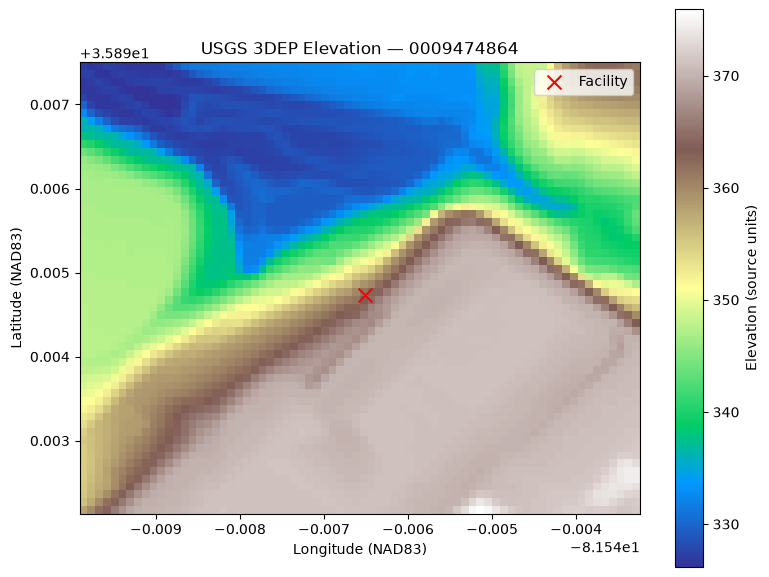

In [25]:
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

with rasterio.open(output_path) as src:
    dem = src.read(1, masked=True)
    extent = plotting_extent(src)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    dem,
    cmap="terrain",
    extent=extent,
    origin="upper"
)

# Facility coordinates transformed into DEM CRS
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:4269",
    always_xy=True
)

facility_x, facility_y = transformer.transform(lon, lat)

ax.scatter(
    facility_x,
    facility_y,
    color="red",
    marker="x",
    s=100,
    label="Facility"
)

ax.set_title(f"USGS 3DEP Elevation — {test_row['id']}")
ax.set_xlabel("Longitude (NAD83)")
ax.set_ylabel("Latitude (NAD83)")
ax.legend()

plt.colorbar(im, ax=ax, label="Elevation (source units)")
plt.tight_layout()
plt.show()

# batch extraction

In [26]:
from pathlib import Path
import rasterio
import numpy as np

from rasterio.windows import from_bounds, transform as window_transform
from rasterio.warp import transform_bounds

def extract_facility_dem(row, output_dir=Path("Data/temp/usgs_3dep")):
    facility_id = str(row["id"])
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"{facility_id}_dem.tif"

    result = {
        "id": facility_id,
        "product_date": row["product_date"],
        "dem_url": row["dem_url"],
        "output_path": str(output_path),
        "status": None,
        "crs": None,
        "resolution": None,
        "shape": None,
        "valid_pixels": None,
        "missing_pixels": None,
    }

    if output_path.exists():
        result["status"] = "skipped_existing"
        return result

    try:
        with rasterio.Env(
            GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
            CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
            GDAL_HTTP_TIMEOUT="60",
        ):
            with rasterio.open(row["dem_url"]) as src:

                dem_bbox = transform_bounds(
                    "EPSG:4326",
                    src.crs,
                    *row["bbox"],
                    densify_pts=21,
                )

                covered = (
                    src.bounds.left <= dem_bbox[0]
                    and src.bounds.bottom <= dem_bbox[1]
                    and src.bounds.right >= dem_bbox[2]
                    and src.bounds.top >= dem_bbox[3]
                )

                if not covered:
                    raise ValueError("Selected DEM does not cover full footprint")

                window = from_bounds(
                    *dem_bbox,
                    transform=src.transform,
                ).round_offsets().round_lengths()

                elevation = src.read(1, window=window, masked=True)

                if elevation.count() == 0:
                    raise ValueError("No valid elevation pixels")

                profile = src.profile.copy()
                profile.update(
                    height=elevation.shape[0],
                    width=elevation.shape[1],
                    transform=window_transform(window, src.transform),
                )

                result.update({
                    "crs": str(src.crs),
                    "resolution": tuple(src.res),
                    "shape": tuple(elevation.shape),
                    "valid_pixels": int(elevation.count()),
                    "missing_pixels": int(np.ma.count_masked(elevation)),
                })

                nodata = src.nodata

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(elevation.filled(nodata), 1)

        result["status"] = "success"

    except Exception as exc:
        result["status"] = "error"
        result["error"] = str(exc)

    return result

In [27]:
batch_results = []

for _, row in selected_dems.iterrows():
    result = extract_facility_dem(row)
    batch_results.append(result)

    print(f"{result['id']}: {result['status']}")

batch_results_df = pd.DataFrame(batch_results)

display(
    batch_results_df[
        ["id", "status", "shape", "valid_pixels", "missing_pixels"]
    ]
)

0009474864: skipped_existing
0014930068: skipped_existing
0016282459: skipped_existing
0025706343: skipped_existing
0032560292: skipped_existing
0035491576: skipped_existing
0038305431: skipped_existing
0039083830: skipped_existing
0046831933: skipped_existing
0052059176: skipped_existing


,id,status,shape,valid_pixels,missing_pixels
0,0009474864,skipped_existing,None,None,None
1,0014930068,skipped_existing,None,None,None
2,0016282459,skipped_existing,None,None,None
3,0025706343,skipped_existing,None,None,None
4,0032560292,skipped_existing,None,None,None
5,0035491576,skipped_existing,None,None,None
6,0038305431,skipped_existing,None,None,None
7,0039083830,skipped_existing,None,None,None
8,0046831933,skipped_existing,None,None,None
9,0052059176,skipped_existing,None,None,None


#validate prelim

In [28]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

validation_rows = []

for _, row in batch_manifest.iterrows():
    path = Path("Data/temp/usgs_3dep") / f"{row['id']}_dem.tif"

    if not path.exists():
        validation_rows.append({
            "id": row["id"],
            "status": "missing_file"
        })
        continue

    with rasterio.open(path) as src:
        dem = src.read(1, masked=True)

        validation_rows.append({
            "id": row["id"],
            "status": "valid" if dem.count() > 0 else "no_valid_pixels",
            "shape": dem.shape,
            "valid_pixels": int(dem.count()),
            "missing_pixels": int(np.ma.count_masked(dem)),
            "crs": str(src.crs),
            "nodata": src.nodata
        })

validation_df = pd.DataFrame(validation_rows)

display(validation_df)

print("\nStatus summary:")
print(validation_df["status"].value_counts())

,id,status,shape,valid_pixels,missing_pixels,crs,nodata
0,0009474864,valid,"(58, 72)",4176,0,EPSG:4269,-999999.0
1,0014930068,valid,"(58, 71)",4118,0,EPSG:4269,-999999.0
2,0016282459,valid,"(58, 75)",4350,0,EPSG:4269,-999999.0
3,0025706343,valid,"(58, 69)",4002,0,EPSG:4269,-999999.0
4,0032560292,valid,"(58, 74)",4292,0,EPSG:4269,-999999.0
5,0035491576,valid,"(58, 73)",4234,0,EPSG:4269,-999999.0
6,0038305431,valid,"(58, 73)",4234,0,EPSG:4269,-999999.0
7,0039083830,valid,"(58, 70)",4060,0,EPSG:4269,-999999.0
8,0046831933,valid,"(58, 75)",4350,0,EPSG:4269,-999999.0
9,0052059176,valid,"(58, 83)",4814,0,EPSG:4269,-999999.0



Status summary:
status
valid    10
Name: count, dtype: int64


# another batch 

In [29]:
next_batch = naip_manifest.iloc[10:30].copy()

print("Next batch size:", len(next_batch))
print("Unique IDs:", next_batch["id"].nunique())
print("Missing coordinates:",
      next_batch[["lat", "lon"]].isna().any(axis=1).sum())

display(next_batch[["id", "lat", "lon"]].head())

Next batch size: 20
Unique IDs: 20
Missing coordinates: 0


,id,lat,lon
10,0052094269,39.023907,-77.415190
11,0052094270,39.023321,-77.413201
12,0052227492,44.851593,-93.598831
13,0063619642,44.971302,-93.254652
14,0079298926,38.950586,-77.364548


In [30]:
next_discovery_rows = []

for _, row in next_batch.iterrows():
    facility_id = row["id"]

    facility_bbox = preliminary_bbox(
        float(row["lat"]),
        float(row["lon"])
    )

    try:
        response = requests.get(
            "https://tnmaccess.nationalmap.gov/api/v1/products",
            params={
                "bbox": ",".join(map(str, facility_bbox)),
                "datasets": "National Elevation Dataset (NED) 1/3 arc-second",
                "max": 100
            },
            timeout=60
        )

        response.raise_for_status()

        data = response.json()
        items = data.get("items", [])

        candidates = [
            item for item in items
            if item.get("downloadURL", "").lower().endswith(".tif")
        ]

        next_discovery_rows.append({
            "id": facility_id,
            "bbox": facility_bbox,
            "available_tiles": len(candidates),
            "status": "found" if candidates else "missing",
            "candidate_urls": [
                item["downloadURL"] for item in candidates
            ]
        })

    except requests.RequestException as exc:
        next_discovery_rows.append({
            "id": facility_id,
            "bbox": facility_bbox,
            "available_tiles": 0,
            "status": f"error: {exc}",
            "candidate_urls": []
        })

next_discovery_df = pd.DataFrame(next_discovery_rows)

display(
    next_discovery_df[
        ["id", "available_tiles", "status"]
    ]
)

print("\nCoverage summary:")
print(next_discovery_df["status"].value_counts())

,id,available_tiles,status
0,0052094269,9,found
1,0052094270,9,found
2,0052227492,6,found
3,0063619642,6,found
4,0079298926,8,found
5,0095782052,5,found
6,0104082694,4,found
7,0122665255,8,found
8,0131891022,6,found
9,0152163711,6,found



Coverage summary:
status
found    20
Name: count, dtype: int64


In [31]:
import re
from pathlib import Path

next_selection_rows = []

for _, row in next_discovery_df.iterrows():
    candidates = []

    for url in row["candidate_urls"]:
        filename = Path(url).name
        match = re.search(r"_(\d{8})\.tif$", filename, re.I)

        if match:
            candidates.append({
                "url": url,
                "date": match.group(1)
            })

    if candidates:
        selected = max(candidates, key=lambda x: x["date"])

        next_selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": selected["url"],
            "product_date": selected["date"],
            "status": "selected"
        })
    else:
        next_selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": None,
            "product_date": None,
            "status": "no_dated_candidate"
        })

next_selected_dems = pd.DataFrame(next_selection_rows)

display(
    next_selected_dems[
        ["id", "product_date", "status"]
    ]
)

print("\nSelection summary:")
print(next_selected_dems["status"].value_counts())

,id,product_date,status
0,0052094269,20260512,selected
1,0052094270,20260512,selected
2,0052227492,20260120,selected
3,0063619642,20260120,selected
4,0079298926,20260407,selected
5,0095782052,20260917,selected
6,0104082694,20221218,selected
7,0122665255,20260917,selected
8,0131891022,20260601,selected
9,0152163711,20260601,selected



Selection summary:
status
selected    20
Name: count, dtype: int64


In [32]:
next_batch_results = []

for _, row in next_selected_dems.iterrows():
    result = extract_facility_dem(row)
    next_batch_results.append(result)

    print(f"{result['id']}: {result['status']}")

next_batch_results_df = pd.DataFrame(next_batch_results)

display(
    next_batch_results_df[
        ["id", "status", "shape", "valid_pixels", "missing_pixels"]
    ]
)

print("\nExtraction summary:")
print(next_batch_results_df["status"].value_counts())

0052094269: skipped_existing
0052094270: skipped_existing
0052227492: skipped_existing
0063619642: skipped_existing
0079298926: skipped_existing
0095782052: skipped_existing
0104082694: skipped_existing
0122665255: skipped_existing
0131891022: skipped_existing
0152163711: skipped_existing
0155739337: skipped_existing
0156520409: skipped_existing
0157362579: skipped_existing
0161126131: skipped_existing
0169170979: skipped_existing
0172739953: skipped_existing
0174242795: skipped_existing
0191655977: skipped_existing
0193611192: skipped_existing
0195165330: skipped_existing


,id,status,shape,valid_pixels,missing_pixels
0,0052094269,skipped_existing,None,None,None
1,0052094270,skipped_existing,None,None,None
2,0052227492,skipped_existing,None,None,None
3,0063619642,skipped_existing,None,None,None
4,0079298926,skipped_existing,None,None,None
5,0095782052,skipped_existing,None,None,None
6,0104082694,skipped_existing,None,None,None
7,0122665255,skipped_existing,None,None,None
8,0131891022,skipped_existing,None,None,None
9,0152163711,skipped_existing,None,None,None



Extraction summary:
status
skipped_existing    20
Name: count, dtype: int64


# inspect 2 errors

In [33]:
failed_dems = next_batch_results_df[
    next_batch_results_df["status"] == "error"
]

display(
    failed_dems[
        ["id", "error", "dem_url"]
    ]
)

KeyError: "['error'] not in index"

# check alternative

In [ ]:
failed_ids = ["0169170979", "0174242795"]

for facility_id in failed_ids:
    row = next_discovery_df.loc[
        next_discovery_df["id"] == facility_id
    ].iloc[0]

    print(f"\nFacility: {facility_id}")

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
        CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
        GDAL_HTTP_TIMEOUT="60",
    ):
        for url in row["candidate_urls"]:
            try:
                with rasterio.open(url) as src:
                    dem_bbox = transform_bounds(
                        "EPSG:4326",
                        src.crs,
                        *row["bbox"],
                        densify_pts=21
                    )

                    covered = (
                        src.bounds.left <= dem_bbox[0]
                        and src.bounds.bottom <= dem_bbox[1]
                        and src.bounds.right >= dem_bbox[2]
                        and src.bounds.top >= dem_bbox[3]
                    )

                    print(
                        Path(url).name,
                        "| Full coverage:", covered
                    )

            except Exception as exc:
                print(
                    Path(url).name,
                    "| Error:", str(exc)[:120]
                )


Facility: 0169170979
USGS_13_n35w107_20011201.tif | Full coverage: True
USGS_13_n35w107_20210630.tif | Full coverage: True
USGS_13_n35w107_20220721.tif | Full coverage: True
USGS_13_n35w107_20220801.tif | Full coverage: True
USGS_13_n35w107_20231208.tif | Full coverage: True
USGS_13_n36w107_20010601.tif | Full coverage: False
USGS_13_n36w107_20210630.tif | Full coverage: False
USGS_13_n36w107_20220801.tif | Full coverage: False
USGS_13_n36w107_20231208.tif | Full coverage: False
USGS_13_n36w107_20240308.tif | Full coverage: False
USGS_13_n36w107_20240416.tif | Full coverage: False
USGS_13_n35w107_20190712.tif | Full coverage: True
USGS_13_n36w107_20190712.tif | Full coverage: False

Facility: 0174242795
USGS_13_n42w088_20120801.tif | Full coverage: False
USGS_13_n42w088_20210617.tif | Full coverage: False
USGS_13_n42w088_20240104.tif | Full coverage: False
USGS_13_n42w088_20241107.tif | Full coverage: False
USGS_13_n42w088_20260323.tif | Full coverage: False
USGS_13_n42w088_20260902.t

# recover first failed

In [ ]:
facility_id = "0169170979"

row = next_selected_dems.loc[
    next_selected_dems["id"] == facility_id
].iloc[0].copy()

row["dem_url"] = next(
    url
    for url in next_discovery_df.loc[
        next_discovery_df["id"] == facility_id,
        "candidate_urls"
    ].iloc[0]
    if "USGS_13_n35w107_20231208.tif" in url
)

row["product_date"] = "20231208"

result = extract_facility_dem(row)

print("Facility:", result["id"])
print("Status:", result["status"])
print("Shape:", result["shape"])
print("Valid pixels:", result["valid_pixels"])
print("Missing pixels:", result["missing_pixels"])

if result["status"] == "error":
    print("Error:", result.get("error"))

Facility: 0169170979
Status: success
Shape: (58, 71)
Valid pixels: 4118
Missing pixels: 0


# inspecting tile boundry issue 

In [ ]:
facility_id = "0174242795"

candidate_urls = next_discovery_df.loc[
    next_discovery_df["id"] == facility_id,
    "candidate_urls"
].iloc[0]

# Select matching 2024 versions from both adjacent tiles
mosaic_urls = [
    url for url in candidate_urls
    if (
        "USGS_13_n42w088_20241107.tif" in url
        or "USGS_13_n43w088_20241107.tif" in url
    )
]

with rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60"
):
    for url in mosaic_urls:
        with rasterio.open(url) as src:
            print("\nTile:", Path(url).name)
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Bounds:", src.bounds)
            print("NoData:", src.nodata)

print("\nTiles found:", len(mosaic_urls))


Tile: USGS_13_n42w088_20241107.tif
CRS: EPSG:4269
Resolution: (9.25925927753796e-05, 9.259259269219641e-05)
Bounds: BoundingBox(left=-88.00055555649311, bottom=40.999444443806965, right=-86.99944444340571, top=42.00055555599499)
NoData: -999999.0

Tile: USGS_13_n43w088_20241107.tif
CRS: EPSG:4269
Resolution: (9.25925927753796e-05, 9.259259269220167e-05)
Bounds: BoundingBox(left=-88.00055555649311, bottom=41.9994444436071, right=-86.99944444340571, top=43.00055555579519)
NoData: -999999.0

Tiles found: 2


# 2 tile mosaic extract for missing

In [ ]:
from contextlib import ExitStack
from rasterio.merge import merge
from rasterio.warp import transform_bounds
from pathlib import Path
import rasterio
import numpy as np

facility_id = "0174242795"

row = next_selected_dems.loc[
    next_selected_dems["id"] == facility_id
].iloc[0]

output_dir = Path("Data/temp/usgs_3dep")
output_path_mosaic = output_dir / f"{facility_id}_dem.tif"

if output_path_mosaic.exists():
    raise FileExistsError(
        f"Output already exists: {output_path_mosaic}"
    )

with rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60",
):
    with ExitStack() as stack:
        sources = [
            stack.enter_context(rasterio.open(url))
            for url in mosaic_urls
        ]

        # Transform WGS84 facility footprint into source CRS
        dem_bbox = transform_bounds(
            "EPSG:4326",
            sources[0].crs,
            *row["bbox"],
            densify_pts=21
        )

        mosaic, mosaic_transform = merge(
            sources,
            bounds=dem_bbox,
            res=sources[0].res,
            nodata=sources[0].nodata,
            masked=False
        )

        profile = sources[0].profile.copy()
        profile.update(
            height=mosaic.shape[1],
            width=mosaic.shape[2],
            transform=mosaic_transform,
            count=1
        )

nodata = profile["nodata"]
valid_mask = np.isfinite(mosaic[0]) & (mosaic[0] != nodata)

print("Mosaic shape:", mosaic.shape)
print("Valid pixels:", int(valid_mask.sum()))
print("Missing pixels:", int((~valid_mask).sum()))

if not valid_mask.all():
    raise ValueError("Mosaic contains missing elevation pixels")

output_dir.mkdir(parents=True, exist_ok=True)

with rasterio.open(output_path_mosaic, "w", **profile) as dst:
    dst.write(mosaic)

print("Saved:", output_path_mosaic)

Mosaic shape: (1, 58, 78)
Valid pixels: 4524
Missing pixels: 0
Saved: Data/temp/usgs_3dep/0174242795_dem.tif


# validate all 30 saved

In [ ]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd
from rasterio.warp import transform_bounds

validation_rows = []

for _, row in naip_manifest.head(30).iterrows():
    path = Path("Data/temp/usgs_3dep") / f"{row['id']}_dem.tif"

    if not path.exists():
        validation_rows.append({
            "id": row["id"],
            "status": "missing_file"
        })
        continue

    with rasterio.open(path) as src:
        dem = src.read(1, masked=True)

        west, south, east, north = transform_bounds(
            src.crs, "EPSG:4326", *src.bounds
        )

        facility_inside = (
            west <= float(row["lon"]) <= east
            and south <= float(row["lat"]) <= north
        )

        valid = int(dem.count())
        missing = int(np.ma.count_masked(dem))

        validation_rows.append({
            "id": row["id"],
            "status": (
                "valid" if valid > 0 and missing == 0 and facility_inside
                else "check_required"
            ),
            "shape": dem.shape,
            "valid_pixels": valid,
            "missing_pixels": missing,
            "facility_inside": facility_inside,
            "crs": str(src.crs)
        })

validation_30_df = pd.DataFrame(validation_rows)

display(validation_30_df)

print("\nValidation summary:")
print(validation_30_df["status"].value_counts())

,id,status,shape,valid_pixels,missing_pixels,facility_inside,crs
0,0009474864,valid,"(58, 72)",4176,0,True,EPSG:4269
1,0014930068,valid,"(58, 71)",4118,0,True,EPSG:4269
2,0016282459,valid,"(58, 75)",4350,0,True,EPSG:4269
3,0025706343,valid,"(58, 69)",4002,0,True,EPSG:4269
4,0032560292,valid,"(58, 74)",4292,0,True,EPSG:4269
5,0035491576,valid,"(58, 73)",4234,0,True,EPSG:4269
6,0038305431,valid,"(58, 73)",4234,0,True,EPSG:4269
7,0039083830,valid,"(58, 70)",4060,0,True,EPSG:4269
8,0046831933,valid,"(58, 75)",4350,0,True,EPSG:4269
9,0052059176,valid,"(58, 83)",4814,0,True,EPSG:4269



Validation summary:
status
valid    30
Name: count, dtype: int64


## preparing to extract rest

In [ ]:
from pathlib import Path

dem_dir = Path("Data/temp/usgs_3dep")

remaining_manifest = naip_manifest.iloc[30:].copy()

remaining_manifest["dem_exists"] = remaining_manifest["id"].apply(
    lambda fid: (dem_dir / f"{fid}_dem.tif").exists()
)

print("Remaining facilities:", len(remaining_manifest))
print("Existing DEM files:", remaining_manifest["dem_exists"].sum())
print("Missing DEM files:", (~remaining_manifest["dem_exists"]).sum())

display(
    remaining_manifest[
        ["id", "lat", "lon", "dem_exists"]
    ].head(10)
)

Remaining facilities: 232
Existing DEM files: 0
Missing DEM files: 232


,id,lat,lon,dem_exists
30,0195165354,39.295658,-94.673472,False
31,0195165374,39.295492,-94.678025,False
32,0195664350,36.262546,-95.910031,False
33,0199252950,41.796674,-88.243537,False
34,0204316962,40.520901,-74.347317,False
35,0204460950,40.553779,-74.457179,False
36,0209073657,37.375023,-121.958096,False
37,0209087373,37.372250,-121.948329,False
38,0209786637,41.842187,-87.669008,False
39,0210222970,41.848797,-87.645510,False


## coverage aware selector

In [ ]:
def find_covering_dem_tiles(bbox, candidate_urls):
    """
    Inspect USGS DEM candidates and identify tiles
    that fully cover the requested WGS84 bounding box.
    """
    results = []

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
        CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
        GDAL_HTTP_TIMEOUT="60",
    ):
        for url in candidate_urls:
            try:
                with rasterio.open(url) as src:
                    dem_bbox = transform_bounds(
                        "EPSG:4326",
                        src.crs,
                        *bbox,
                        densify_pts=21,
                    )

                    full_coverage = (
                        src.bounds.left <= dem_bbox[0]
                        and src.bounds.bottom <= dem_bbox[1]
                        and src.bounds.right >= dem_bbox[2]
                        and src.bounds.top >= dem_bbox[3]
                    )

                    results.append({
                        "url": url,
                        "filename": Path(url).name,
                        "full_coverage": full_coverage,
                        "crs": str(src.crs),
                        "resolution": tuple(src.res),
                        "bounds": tuple(src.bounds),
                        "status": "ok",
                    })

            except Exception as exc:
                results.append({
                    "url": url,
                    "filename": Path(url).name,
                    "full_coverage": False,
                    "status": "error",
                    "error": str(exc),
                })

    return pd.DataFrame(results)


for facility_id in ["0169170979", "0174242795"]:
    row = next_discovery_df.loc[
        next_discovery_df["id"] == facility_id
    ].iloc[0]

    coverage_df = find_covering_dem_tiles(
        row["bbox"],
        row["candidate_urls"],
    )

    print(f"\nFacility: {facility_id}")
    print("Candidates:", len(coverage_df))
    print("Fully covering:", coverage_df["full_coverage"].sum())
    print("Metadata errors:", (coverage_df["status"] == "error").sum())


Facility: 0169170979
Candidates: 13
Fully covering: 6
Metadata errors: 0

Facility: 0174242795
Candidates: 12
Fully covering: 0
Metadata errors: 0


# automatically selects newest available dem

In [ ]:
import re
import pandas as pd

def select_latest_covering_dem(coverage_df):
    covering = coverage_df.loc[
        (coverage_df["status"] == "ok")
        & (coverage_df["full_coverage"])
    ].copy()

    if covering.empty:
        return None

    # Extract product dates from USGS filenames
    covering["product_date"] = covering["filename"].str.extract(
        r"_(\d{8})\.tif$"
    )[0]

    covering["parsed_date"] = pd.to_datetime(
        covering["product_date"],
        format="%Y%m%d",
        errors="coerce"
    )

    covering = covering.dropna(subset=["parsed_date"])

    if covering.empty:
        return None

    selected = covering.sort_values(
        ["parsed_date", "filename"],
        ascending=[False, True]
    ).iloc[0]

    return {
        "dem_url": selected["url"],
        "product_date": selected["product_date"],
        "filename": selected["filename"],
    }


# Test both previously problematic facilities
for facility_id in ["0169170979", "0174242795"]:
    row = next_discovery_df.loc[
        next_discovery_df["id"] == facility_id
    ].iloc[0]

    coverage_df = find_covering_dem_tiles(
        row["bbox"],
        row["candidate_urls"]
    )

    selected = select_latest_covering_dem(coverage_df)

    print(f"\nFacility: {facility_id}")
    print("Selected:", selected)


Facility: 0169170979
Selected: {'dem_url': 'https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n35w107/USGS_13_n35w107_20231208.tif', 'product_date': '20231208', 'filename': 'USGS_13_n35w107_20231208.tif'}

Facility: 0174242795
Selected: None


# automatic mosaic selection

In [ ]:
def select_mosaic_candidates(coverage_df):
    candidates = coverage_df.loc[
        coverage_df["status"] == "ok"
    ].copy()

    candidates["tile_id"] = candidates["filename"].str.extract(
        r"USGS_13_(n\d{2}w\d{3})_"
    )[0]

    candidates["product_date"] = candidates["filename"].str.extract(
        r"_(\d{8})\.tif$"
    )[0]

    candidates["parsed_date"] = pd.to_datetime(
        candidates["product_date"],
        format="%Y%m%d",
        errors="coerce"
    )

    candidates = candidates.dropna(
        subset=["tile_id", "parsed_date"]
    )

    if candidates.empty:
        return pd.DataFrame()

    latest = (
        candidates
        .sort_values("parsed_date", ascending=False)
        .drop_duplicates(subset=["tile_id"], keep="first")
        .sort_values("tile_id")
        .reset_index(drop=True)
    )

    return latest[
        ["tile_id", "filename", "product_date", "url"]
    ]


# Test the known multi-tile facility
facility_id = "0174242795"

row = next_discovery_df.loc[
    next_discovery_df["id"] == facility_id
].iloc[0]

coverage_df = find_covering_dem_tiles(
    row["bbox"],
    row["candidate_urls"]
)

mosaic_candidates_df = select_mosaic_candidates(coverage_df)

display(mosaic_candidates_df)

,tile_id,filename,product_date,url
0,n42w088,USGS_13_n42w088_20260902.tif,20260902,https://prd-tnm.s3.amazonaws.com/StagedProduct...
1,n43w088,USGS_13_n43w088_20241107.tif,20241107,https://prd-tnm.s3.amazonaws.com/StagedProduct...


# evrify

In [ ]:
from rasterio.coords import BoundingBox

with rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60",
):
    tile_info = []

    for _, row in mosaic_candidates_df.iterrows():
        with rasterio.open(row["url"]) as src:
            tile_info.append({
                "tile_id": row["tile_id"],
                "filename": row["filename"],
                "crs": str(src.crs),
                "resolution": src.res,
                "bounds": src.bounds,
                "nodata": src.nodata,
            })

    for tile in tile_info:
        print("\nTile:", tile["filename"])
        print("CRS:", tile["crs"])
        print("Resolution:", tile["resolution"])
        print("Bounds:", tile["bounds"])
        print("NoData:", tile["nodata"])

    same_crs = len({t["crs"] for t in tile_info}) == 1

    same_nodata = len({
        t["nodata"] for t in tile_info
    }) == 1

    compatible_resolution = all(
        np.allclose(
            tile_info[0]["resolution"],
            t["resolution"],
            rtol=1e-6,
            atol=0
        )
        for t in tile_info[1:]
    )

    print("\nSame CRS:", same_crs)
    print("Same NoData:", same_nodata)
    print("Compatible resolution:", compatible_resolution)


Tile: USGS_13_n42w088_20260902.tif
CRS: EPSG:4269
Resolution: (9.25925927753796e-05, 9.259259269219641e-05)
Bounds: BoundingBox(left=-88.00055555649311, bottom=40.999444443806965, right=-86.99944444340571, top=42.00055555599499)
NoData: -999999.0

Tile: USGS_13_n43w088_20241107.tif
CRS: EPSG:4269
Resolution: (9.25925927753796e-05, 9.259259269220167e-05)
Bounds: BoundingBox(left=-88.00055555649311, bottom=41.9994444436071, right=-86.99944444340571, top=43.00055555579519)
NoData: -999999.0

Same CRS: True
Same NoData: True
Compatible resolution: True


# verify geo coverage

In [ ]:
from shapely.geometry import box
from shapely.ops import unary_union
from rasterio.warp import transform_bounds

facility_id = "0174242795"

facility_row = next_discovery_df.loc[
    next_discovery_df["id"] == facility_id
].iloc[0]

# Convert the facility footprint from WGS84 to DEM CRS
dem_bbox = transform_bounds(
    "EPSG:4326",
    tile_info[0]["crs"],
    *facility_row["bbox"],
    densify_pts=21
)

facility_polygon = box(*dem_bbox)

# Combine geographic coverage of selected tiles
tile_polygons = [
    box(*tile["bounds"])
    for tile in tile_info
]

combined_coverage = unary_union(tile_polygons)

fully_covered = combined_coverage.covers(facility_polygon)

print("Facility DEM bbox:", dem_bbox)
print("Number of tiles:", len(tile_polygons))
print("Combined coverage:", fully_covered)
print(
    "Uncovered area:",
    facility_polygon.difference(combined_coverage).area
)

Facility DEM bbox: (-87.95441755563037, 41.998067087575244, -87.94717553150171, 42.00346892589359)
Number of tiles: 2
Combined coverage: True
Uncovered area: 0.0


# test automatic mosaic

In [ ]:
from contextlib import ExitStack
from rasterio.merge import merge
from rasterio.warp import transform_bounds
import rasterio
import numpy as np

def build_facility_mosaic(bbox, tile_urls):
    """
    Build an in-memory DEM mosaic for a WGS84 facility bbox.
    Does not save or overwrite files.
    """

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
        CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
        GDAL_HTTP_TIMEOUT="60",
    ):
        with ExitStack() as stack:
            sources = [
                stack.enter_context(rasterio.open(url))
                for url in tile_urls
            ]

            crs = sources[0].crs
            nodata = sources[0].nodata

            if any(src.crs != crs for src in sources):
                raise ValueError("Mosaic sources have different CRSs")

            if any(
                not np.allclose(src.res, sources[0].res, rtol=1e-6)
                for src in sources
            ):
                raise ValueError("Mosaic sources have incompatible resolutions")

            if any(src.nodata != nodata for src in sources):
                raise ValueError("Mosaic sources have different NoData values")

            dem_bbox = transform_bounds(
                "EPSG:4326",
                crs,
                *bbox,
                densify_pts=21
            )

            mosaic, transform = merge(
                sources,
                bounds=dem_bbox,
                res=sources[0].res,
                nodata=nodata,
                method="first"
            )

            profile = sources[0].profile.copy()
            profile.update(
                height=mosaic.shape[1],
                width=mosaic.shape[2],
                count=1,
                transform=transform
            )

    valid_mask = np.isfinite(mosaic[0]) & (mosaic[0] != nodata)

    if not valid_mask.all():
        raise ValueError("Mosaic contains missing elevation pixels")

    return mosaic, profile


# Test against our known tile-boundary facility
test_mosaic, test_profile = build_facility_mosaic(
    facility_row["bbox"],
    mosaic_candidates_df["url"].tolist()
)

print("Shape:", test_mosaic.shape)
print("CRS:", test_profile["crs"])
print("Valid pixels:", test_mosaic[0].size)
print("Missing pixels:", np.sum(
    test_mosaic[0] == test_profile["nodata"]
))

Shape: (1, 58, 78)
CRS: EPSG:4269
Valid pixels: 4524
Missing pixels: 0


# combine

In [ ]:
def prepare_facility_dem(bbox, candidate_urls):
    """
    Select a covering DEM or build a multi-tile mosaic.
    Returns the raster, GeoTIFF profile, and provenance.
    Does not write files.
    """

    coverage_df = find_covering_dem_tiles(
        bbox, candidate_urls
    )

    selected = select_latest_covering_dem(coverage_df)

    if selected is not None:
        method = "single_tile"
        urls = [selected["dem_url"]]

    else:
        method = "mosaic"

        mosaic_candidates = select_mosaic_candidates(
            coverage_df
        )

        if mosaic_candidates.empty:
            raise ValueError("No usable DEM candidates")

        urls = mosaic_candidates["url"].tolist()

    # Works for both one source and multiple sources
    dem, profile = build_facility_mosaic(bbox, urls)

    provenance = {
        "method": method,
        "source_urls": urls,
        "source_count": len(urls),
        "source_filenames": [
            Path(url).name for url in urls
        ],
    }

    return dem, profile, provenance


# Test both previously problematic facilities
for facility_id in ["0169170979", "0174242795"]:

    row = next_discovery_df.loc[
        next_discovery_df["id"] == facility_id
    ].iloc[0]

    dem, profile, provenance = prepare_facility_dem(
        row["bbox"],
        row["candidate_urls"]
    )

    print(f"\nFacility: {facility_id}")
    print("Method:", provenance["method"])
    print("Sources:", provenance["source_count"])
    print("Shape:", dem.shape)
    print("CRS:", profile["crs"])
    print("Source files:", provenance["source_filenames"])


Facility: 0169170979
Method: single_tile
Sources: 1
Shape: (1, 58, 71)
CRS: EPSG:4269
Source files: ['USGS_13_n35w107_20231208.tif']

Facility: 0174242795
Method: mosaic
Sources: 2
Shape: (1, 58, 78)
CRS: EPSG:4269
Source files: ['USGS_13_n42w088_20260902.tif', 'USGS_13_n43w088_20241107.tif']


# filter mosaic candidates

In [ ]:
from shapely.geometry import box

def select_mosaic_candidates(coverage_df, bbox):
    """
    Select the newest available product per geographic tile,
    restricted to tiles intersecting the facility footprint.

    bbox is in EPSG:4326.
    """
    candidates = coverage_df.loc[
        coverage_df["status"] == "ok"
    ].copy()

    candidates["tile_id"] = candidates["filename"].str.extract(
        r"USGS_13_(n\d{2}w\d{3})_"
    )[0]

    candidates["product_date"] = candidates["filename"].str.extract(
        r"_(\d{8})\.tif$"
    )[0]

    candidates["parsed_date"] = pd.to_datetime(
        candidates["product_date"],
        format="%Y%m%d",
        errors="coerce"
    )

    candidates = candidates.dropna(
        subset=["tile_id", "parsed_date"]
    ).copy()

    if candidates.empty:
        return candidates

    # Check intersection in each source's CRS
    def intersects_footprint(row):
        dem_bbox = transform_bounds(
            "EPSG:4326",
            row["crs"],
            *bbox,
            densify_pts=21
        )

        return box(*row["bounds"]).intersects(
            box(*dem_bbox)
        )

    candidates = candidates.loc[
        candidates.apply(intersects_footprint, axis=1)
    ].copy()

    latest = (
        candidates
        .sort_values(
            ["parsed_date", "filename"],
            ascending=[False, True]
        )
        .drop_duplicates(subset=["tile_id"], keep="first")
        .sort_values("tile_id")
        .reset_index(drop=True)
    )

    return latest[
        ["tile_id", "filename", "product_date", "url"]
    ]


# Test the improved selector
facility_id = "0174242795"

row = next_discovery_df.loc[
    next_discovery_df["id"] == facility_id
].iloc[0]

coverage_df = find_covering_dem_tiles(
    row["bbox"],
    row["candidate_urls"]
)

filtered_mosaic_df = select_mosaic_candidates(
    coverage_df,
    row["bbox"]
)

display(filtered_mosaic_df)

print("Selected tiles:", len(filtered_mosaic_df))

,tile_id,filename,product_date,url
0,n42w088,USGS_13_n42w088_20260902.tif,20260902,https://prd-tnm.s3.amazonaws.com/StagedProduct...
1,n43w088,USGS_13_n43w088_20241107.tif,20241107,https://prd-tnm.s3.amazonaws.com/StagedProduct...


Selected tiles: 2


# automatic validation

In [ ]:
from shapely.geometry import box
from shapely.ops import unary_union
from rasterio.warp import transform_bounds

def validate_mosaic_coverage(coverage_df, selected_df, bbox):
    """
    Verify that selected DEM tiles collectively cover
    the requested WGS84 facility footprint.

    Returns True or False.
    """
    if selected_df.empty:
        return False

    selected_metadata = coverage_df.loc[
        coverage_df["url"].isin(selected_df["url"])
        & (coverage_df["status"] == "ok")
    ]

    if len(selected_metadata) != len(selected_df):
        return False

    # Transform all source bounds into a common CRS (EPSG:4326)
    tile_polygons = []

    for _, tile in selected_metadata.iterrows():
        bounds_wgs84 = transform_bounds(
            tile["crs"],
            "EPSG:4326",
            *tile["bounds"],
            densify_pts=21
        )
        tile_polygons.append(box(*bounds_wgs84))

    combined_coverage = unary_union(tile_polygons)
    facility_footprint = box(*bbox)

    return combined_coverage.covers(facility_footprint)


# Test our known tile-boundary facility
coverage_valid = validate_mosaic_coverage(
    coverage_df,
    filtered_mosaic_df,
    row["bbox"]
)

print("Combined coverage valid:", coverage_valid)

Combined coverage valid: True


---
# Production-ready continuation: remaining 232 facilities

The preceding cells document the exploratory work and the **30 locally validated DEMs**. The cells below consolidate that work into a resumable acquisition workflow. Run the original notebook setup cells first to create `naip_manifest` and `preliminary_bbox`; you do **not** need to rerun the historical exploratory pulls.

**Important limitations:** the 300 m radius WGS84 bbox is an **approximation**, not a verified NAIP image footprint; DEM grids are EPSG:4269 at ~10 m, while NAIP PNG dimensions vary. These DEMs are not yet pixel-aligned to NAIP. Source product dates do not guarantee terrain observation dates. This notebook does not upload to S3 or alter existing NAIP objects.

In [34]:
# Final pipeline imports and configuration
from pathlib import Path
from contextlib import ExitStack
from urllib.parse import urlparse
from datetime import datetime, timezone
import json
import re
import time

import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.merge import merge
from rasterio.warp import transform_bounds
from shapely.geometry import box
from shapely.ops import unary_union

DEM_DIR = Path("Data/temp/usgs_3dep")
LOG_DIR = Path("Data/temp/usgs_3dep_logs")
DEM_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

USGS_API = "https://tnmaccess.nationalmap.gov/api/v1/products"
USGS_DATASET = "National Elevation Dataset (NED) 1/3 arc-second"
RASTER_ENV = dict(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_TIMEOUT="60",
)

assert "naip_manifest" in globals(), "Run the notebook's NAIP manifest setup cells first"
assert "preliminary_bbox" in globals(), "Run the preliminary_bbox definition cell first"
assert naip_manifest["id"].astype(str).str.fullmatch(r"\d{10}").all()
assert naip_manifest["id"].is_unique
assert naip_manifest[["lat", "lon"]].notna().all().all()
print("Manifest:", len(naip_manifest), "facilities; local DEM folder:", DEM_DIR)

Manifest: 262 facilities; local DEM folder: Data/temp/usgs_3dep


## 1. Robust USGS discovery and candidate selection

The API may return multiple dated versions of the same tile. We inspect remote raster metadata using GDAL HTTP range reads, prefer the newest **fully covering** product, and otherwise select only the intersecting tiles. A missing/failed candidate is recorded rather than silently treated as a successful search. Candidate inspection may still make many small HTTP requests.

In [35]:
def discover_usgs_candidates(bbox, session=None, attempts=3):
    """Return GeoTIFF URLs; fail loudly on incomplete/paginated API responses."""
    params = {
        "bbox": ",".join(map(str, bbox)),
        "datasets": USGS_DATASET,
        "max": 100,
        "offset": 0,
    }
    http = session or requests
    urls = []
    for page in range(30):
        last_error = None
        for attempt in range(attempts):
            try:
                response = http.get(USGS_API, params=params, timeout=60)
                response.raise_for_status()
                data = response.json()
                break
            except (requests.RequestException, ValueError) as exc:
                last_error = exc
                if attempt + 1 < attempts:
                    time.sleep(min(2 ** attempt, 4))
        else:
            raise RuntimeError(f"USGS discovery failed: {last_error}")

        items = data.get("items", [])
        urls.extend(
            item["downloadURL"] for item in items
            if isinstance(item.get("downloadURL"), str)
            and urlparse(item["downloadURL"]).path.lower().endswith(".tif")
        )
        total = data.get("total")
        params["offset"] += len(items)
        if not items or (total is not None and params["offset"] >= int(total)) or len(items) < params["max"]:
            break
    else:
        raise RuntimeError("USGS API pagination limit reached; results may be incomplete")
    return list(dict.fromkeys(urls))


def inspect_usgs_candidates(bbox, urls):
    rows = []
    with rasterio.Env(**RASTER_ENV):
        for url in urls:
            filename = Path(urlparse(url).path).name
            match = re.search(r"USGS_13_(n\d{2}w\d{3})_(\d{8})\.tif$", filename, re.I)
            try:
                with rasterio.open(url) as src:
                    target = transform_bounds("EPSG:4326", src.crs, *bbox, densify_pts=21)
                    bounds = tuple(src.bounds)
                    rows.append(dict(url=url, filename=filename,
                        tile_id=match.group(1) if match else None,
                        product_date=match.group(2) if match else None,
                        crs=str(src.crs), resolution=tuple(src.res), nodata=src.nodata,
                        bounds=bounds, full_coverage=box(*bounds).covers(box(*target)),
                        intersects=box(*bounds).intersects(box(*target)), status="ok"))
            except Exception as exc:
                rows.append(dict(url=url, filename=filename, status="error", error=str(exc)))
    return pd.DataFrame(rows)


def choose_dem_sources(coverage, bbox):
    """Return (method, ordered source rows). Raise if combined coverage is incomplete."""
    if coverage.empty or "status" not in coverage:
        raise ValueError("No DEM candidate metadata available")
    ok = coverage.loc[coverage["status"].eq("ok")].copy()
    ok = ok.dropna(subset=["product_date", "tile_id"])
    if ok.empty:
        raise ValueError("No readable dated USGS 1/3 arc-second products")
    ok = ok.sort_values(["product_date", "filename"], ascending=[False, True])
    singles = ok.loc[ok["full_coverage"]]
    if not singles.empty:
        return "single_tile", singles.head(1)

    selected = (ok.loc[ok["intersects"]]
                .drop_duplicates(subset=["tile_id"], keep="first")
                .sort_values("tile_id"))
    if selected.empty:
        raise ValueError("No intersecting USGS tiles")
    # Compare in the DEM CRS rather than using approximate transformed rectangles.
    crs_set = set(selected["crs"])
    if len(crs_set) != 1:
        raise ValueError("Selected mosaic sources have different CRSs")
    target = box(*transform_bounds("EPSG:4326", selected.iloc[0]["crs"], *bbox, densify_pts=21))
    union = unary_union([box(*b) for b in selected["bounds"]])
    if not union.covers(target):
        raise ValueError("Selected mosaic tiles do not cover the complete footprint")
    return "mosaic", selected

## 2. Extract, validate, and save safely

This function makes a **small, in-memory crop** of the remote DEM(s), validates all output pixels, and saves the result atomically. Existing outputs are validated and skipped, never overwritten. An accompanying `.json` records source URLs, dates, method, and the provisional bbox. A `.tif` without its JSON metadata is treated as an existing file and is **not** silently replaced.

In [40]:
from shapely import Point


def check_local_dem(path, lat, lon):
    """Validate an existing saved GeoTIFF; returns metadata or raises."""
    with rasterio.open(path) as src:
        if src.count != 1 or src.width <= 0 or src.height <= 0 or src.crs is None:
            raise ValueError("Invalid single-band georeferenced DEM")
        values = src.read(1, masked=True)
        if values.count() != values.size:
            raise ValueError("Missing/NoData pixels in saved DEM")
        if not np.isfinite(values.compressed()).all():
            raise ValueError("Non-finite pixels in saved DEM")
        xy = transform_bounds("EPSG:4326", src.crs, *src.bounds, densify_pts=21)
        if not box(*xy).covers(Point(float(lon), float(lat))):            
                raise ValueError("Facility point is outside saved DEM bounds")
        return {"shape": [src.height, src.width], "crs": str(src.crs),
                "valid_pixels": int(values.count()), "missing_pixels": 0}


def crop_selected_dem(bbox, selected):
    """Windowed read/merge; requires full valid pixel coverage."""
    urls = selected["url"].tolist()
    with rasterio.Env(**RASTER_ENV):
        with ExitStack() as stack:
            sources = [stack.enter_context(rasterio.open(url)) for url in urls]
            ref = sources[0]
            if ref.nodata is None:
                raise ValueError("Source NoData is undefined")
            for src in sources[1:]:
                if src.crs != ref.crs or src.nodata != ref.nodata or not np.allclose(src.res, ref.res, rtol=1e-6, atol=0):
                    raise ValueError("Incompatible mosaic CRS, NoData, or resolution")
            dem_bbox = transform_bounds("EPSG:4326", ref.crs, *bbox, densify_pts=21)
            mosaic, transform = merge(sources, bounds=dem_bbox, res=ref.res,
                                      nodata=ref.nodata, method="first")
            profile = ref.profile.copy()
            profile.update(driver="GTiff", count=1, height=mosaic.shape[1],
                           width=mosaic.shape[2], transform=transform)
    data = mosaic[0]
    good = np.isfinite(data) & (data != profile["nodata"])
    if not good.all():
        raise ValueError(f"DEM contains {int((~good).sum())} invalid pixels")
    return mosaic, profile


def acquire_facility_dem(row, output_dir=DEM_DIR):
    """Resumable, no-overwrite acquisition with a per-facility provenance JSON."""
    fid = str(row["id"]).zfill(10)
    lat, lon = float(row["lat"]), float(row["lon"])
    bbox = preliminary_bbox(lat, lon)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    tif_path = output_dir / f"{fid}_dem.tif"
    json_path = output_dir / f"{fid}_dem.json"
    result = {"id": fid, "output_path": str(tif_path), "status": None,
              "bbox_wgs84_provisional": list(bbox)}
    try:
        if tif_path.exists():
            result.update(check_local_dem(tif_path, lat, lon))
            result["status"] = "skipped_existing"
            result["provenance_exists"] = json_path.exists()
            return result

        urls = discover_usgs_candidates(bbox)
        result["candidate_count"] = len(urls)
        coverage = inspect_usgs_candidates(bbox, urls)
        result["candidate_metadata_errors"] = int((coverage["status"] == "error").sum()) if not coverage.empty else 0
        method, selected = choose_dem_sources(coverage, bbox)
        mosaic, profile = crop_selected_dem(bbox, selected)
        sources = selected[["url", "filename", "tile_id", "product_date"]].to_dict("records")
        provenance = {"id": fid, "lat": lat, "lon": lon,
                      "bbox_wgs84_provisional": list(bbox),
                      "footprint_assumption": "300 m cardinal geodesic radius; NOT verified NAIP extent",
                      "method": method, "sources": sources,
                      "merge_method": "first", "crs": str(profile["crs"]),
                      "shape": [int(mosaic.shape[1]), int(mosaic.shape[2])],
                      "created_utc": datetime.now(timezone.utc).isoformat()}
        tmp_tif = output_dir / f"{fid}_dem.partial.tif"
        tmp_json = output_dir / f"{fid}_dem.partial.json"
        try:
            with rasterio.open(tmp_tif, "w", **profile) as dst:
                dst.write(mosaic)
            checked = check_local_dem(tmp_tif, lat, lon)
            tmp_json.write_text(json.dumps(provenance, indent=2), encoding="utf-8")
            # Re-check before publish. os.link fails if destination exists.
            import os
            os.link(tmp_tif, tif_path)
            os.link(tmp_json, json_path)
        finally:
            tmp_tif.unlink(missing_ok=True)
            tmp_json.unlink(missing_ok=True)
        result.update(checked)
        result.update(status="success", method=method,
                      source_count=len(sources), source_filenames=[s["filename"] for s in sources],
                      provenance_exists=True)
    except Exception as exc:
        result.update(status="error", error=f"{type(exc).__name__}: {exc}")
    return result

## 3. Controlled batches and checkpoints

**Default is a dry run.** Start with a small pilot of five new facilities, inspect the results, and only then enable the remaining 232. The batch results CSV is updated after each facility so interrupted runs can be resumed. Errors are preserved for inspection; rerunning attempts them again. Do not commit the temporary DEM rasters or source URLs if repository policy excludes them.

In [41]:
def run_dem_batch(manifest, log_path=LOG_DIR / "acquisition_results.csv", execute=False):
    """Execute an explicit batch; preserve a checkpoint after each facility."""
    manifest = manifest.copy()
    manifest["id"] = manifest["id"].astype(str).str.zfill(10)
    if manifest["id"].duplicated().any():
        raise ValueError("Duplicate facility IDs in requested batch")
    if not execute:
        print(f"DRY RUN: {len(manifest)} facilities selected; no remote calls or writes.")
        display(manifest[["id", "lat", "lon"]].head(10))
        return None

    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    prior = pd.read_csv(log_path, dtype={"id": str}) if log_path.exists() else pd.DataFrame()
    records = prior.to_dict("records")
    latest = {str(r["id"]).zfill(10): r for r in records}
    for _, row in manifest.iterrows():
        fid = str(row["id"])
        if fid in latest and latest[fid].get("status") in ("success", "skipped_existing"):
            # Existing output still must pass validation before skipping.
            try:
                check_local_dem(DEM_DIR / f"{fid}_dem.tif", row["lat"], row["lon"])
                print(fid, "checkpoint_valid")
                continue
            except Exception:
                pass
        outcome = acquire_facility_dem(row)
        print(fid, outcome["status"], outcome.get("error", ""))
        latest[fid] = outcome
        # Serialize nested fields as JSON strings in the CSV.
        export = []
        for item in latest.values():
            export.append({k: json.dumps(v) if isinstance(v, (list, tuple, dict)) else v
                           for k, v in item.items()})
        tmp_log = log_path.with_suffix(".partial.csv")
        pd.DataFrame(export).to_csv(tmp_log, index=False)
        tmp_log.replace(log_path)
    results = pd.read_csv(log_path, dtype={"id": str})
    print("\nCheckpoint:", log_path)
    print(results["status"].value_counts(dropna=False))
    return results

# Inspect the next five, WITHOUT running anything:
pilot_manifest = naip_manifest.iloc[30:35].copy()
run_dem_batch(pilot_manifest, execute=False)

DRY RUN: 5 facilities selected; no remote calls or writes.


,id,lat,lon
30,0195165354,39.295658,-94.673472
31,0195165374,39.295492,-94.678025
32,0195664350,36.262546,-95.910031
33,0199252950,41.796674,-88.243537
34,0204316962,40.520901,-74.347317


In [42]:
# PILOT — opt in by changing False to True after reviewing the five IDs.
RUN_PILOT = True
if RUN_PILOT:
    pilot_results = run_dem_batch(pilot_manifest, execute=True)
else:
    print("Pilot disabled. Set RUN_PILOT = True when ready.")

0195165354 success 
0195165374 success 
0195664350 success 
0199252950 success 
0204316962 success 

Checkpoint: Data/temp/usgs_3dep_logs/acquisition_results.csv
status
success    5
Name: count, dtype: int64


In [45]:
# FULL REMAINING BATCH — opt in ONLY after the pilot succeeds.
# Safe to rerun: existing valid DEMs are skipped, and checkpoints are preserved.
RUN_REMAINING_232 = True
if RUN_REMAINING_232:
    remaining_manifest = naip_manifest.iloc[30:].copy()
    all_remaining_results = run_dem_batch(remaining_manifest, execute=True)
else:
    print("Full 232-facility acquisition disabled by default.")

0195165354 checkpoint_valid
0195165374 checkpoint_valid
0195664350 checkpoint_valid
0199252950 checkpoint_valid
0204316962 checkpoint_valid
0204460950 success 
0209073657 success 
0209087373 success 
0209786637 success 
0210222970 success 
0215630401 success 
0231047065 success 
0231769626 success 
0233888384 success 
0239032142 success 
0239147724 success 
0244490839 success 
0254742610 success 
0254773884 success 
0256728809 success 
0258519934 success 
0269166415 success 
0269847438 success 
0283051477 success 
0283051482 success 
0283051483 success 
0283051485 success 
0288909509 success 
0289620443 success 
0292506449 success 
0292506452 success 
0293211683 success 
0296374269 success 
0299929061 success 
0300952513 success 
0300959970 success 
0317466755 success 
0318069356 success 
0321385147 success 
0328702378 success 
0337127832 success 
0342664739 success 
0343593591 success 
0362662493 success 
0364289074 success 
0369728508 success 
0377212693 success 
0377545385 success 


## 4. Final local validation and coverage report

This scan is read-only and can be run at any time. A saved raster is considered valid only when it opens correctly, has one georeferenced band, contains no missing/nonfinite pixels, and contains its facility point. It does **not** verify that its footprint matches the NAIP PNG or that elevation units are appropriate for a downstream model.

In [46]:
def validate_local_collection(manifest=naip_manifest, dem_dir=DEM_DIR):
    rows = []
    for _, facility in manifest.iterrows():
        fid = str(facility["id"]).zfill(10)
        path = Path(dem_dir) / f"{fid}_dem.tif"
        provenance = Path(dem_dir) / f"{fid}_dem.json"
        if not path.exists():
            rows.append({"id": fid, "status": "missing", "provenance_exists": False})
            continue
        try:
            details = check_local_dem(path, facility["lat"], facility["lon"])
            rows.append({"id": fid, "status": "valid", "provenance_exists": provenance.exists(), **details})
        except Exception as exc:
            rows.append({"id": fid, "status": "invalid", "error": str(exc),
                         "provenance_exists": provenance.exists()})
    report = pd.DataFrame(rows)
    print("\nDEM validation status:")
    print(report["status"].value_counts(dropna=False))
    print("Provenance JSON available:", int(report["provenance_exists"].sum()), "/", len(report))
    return report

local_validation_report = validate_local_collection()
display(local_validation_report.head(35))


DEM validation status:
status
valid    262
Name: count, dtype: int64
Provenance JSON available: 232 / 262


,id,status,provenance_exists,shape,crs,valid_pixels,missing_pixels
0,0009474864,valid,False,"[58, 72]",EPSG:4269,4176,0
1,0014930068,valid,False,"[58, 71]",EPSG:4269,4118,0
2,0016282459,valid,False,"[58, 75]",EPSG:4269,4350,0
3,0025706343,valid,False,"[58, 69]",EPSG:4269,4002,0
4,0032560292,valid,False,"[58, 74]",EPSG:4269,4292,0
5,0035491576,valid,False,"[58, 73]",EPSG:4269,4234,0
6,0038305431,valid,False,"[58, 73]",EPSG:4269,4234,0
7,0039083830,valid,False,"[58, 70]",EPSG:4269,4060,0
8,0046831933,valid,False,"[58, 75]",EPSG:4269,4350,0
9,0052059176,valid,False,"[58, 83]",EPSG:4269,4814,0


# provenance check

In [47]:
from pathlib import Path
import json

dem_dir = Path("Data/temp/usgs_3dep")

provenance_files = sorted(dem_dir.glob("*.json"))

print("JSON files in DEM directory:", len(provenance_files))

if provenance_files:
    sample = provenance_files[0]
    print("\nSample file:", sample.name)

    with open(sample) as f:
        provenance = json.load(f)

    print(json.dumps(provenance, indent=2))

JSON files in DEM directory: 232

Sample file: 0195165354_dem.json
{
  "id": "0195165354",
  "lat": 39.29565786992253,
  "lon": -94.67347189936218,
  "bbox_wgs84_provisional": [
    -94.67694956615857,
    39.29295568095882,
    -94.6699942325658,
    39.298360057628436
  ],
  "footprint_assumption": "300 m cardinal geodesic radius; NOT verified NAIP extent",
  "method": "single_tile",
  "sources": [
    {
      "url": "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/historical/n40w095/USGS_13_n40w095_20240228.tif",
      "filename": "USGS_13_n40w095_20240228.tif",
      "tile_id": "n40w095",
      "product_date": "20240228"
    }
  ],
  "merge_method": "first",
  "crs": "EPSG:4269",
  "shape": [
    58,
    75
  ],
  "created_utc": "2026-10-19T23:59:59.423408+00:00"
}


# inspect accuisition checkpoint

In [48]:
import pandas as pd
from pathlib import Path

checkpoint_path = Path(
    "Data/temp/usgs_3dep_logs/acquisition_results.csv"
)

checkpoint = pd.read_csv(
    checkpoint_path,
    dtype={"id": str}
)

print("Checkpoint columns:")
print(checkpoint.columns.tolist())

print("\nFirst five records:")
display(checkpoint.head())

print("\nCheckpoint status counts:")
print(checkpoint["status"].value_counts(dropna=False))

Checkpoint columns:
['id', 'output_path', 'status', 'bbox_wgs84_provisional', 'candidate_count', 'candidate_metadata_errors', 'shape', 'crs', 'valid_pixels', 'missing_pixels', 'method', 'source_count', 'source_filenames', 'provenance_exists']

First five records:


,id,output_path,status,bbox_wgs84_provisional,candidate_count,candidate_metadata_errors,shape,crs,valid_pixels,missing_pixels,method,source_count,source_filenames,provenance_exists
0,0195165354,Data/temp/usgs_3dep/0195165354_dem.tif,success,"[-94.67694956615857, 39.29295568095882, -94.66...",6,0,"[58, 75]",EPSG:4269,4350,0,single_tile,1,"[""USGS_13_n40w095_20240228.tif""]",True
1,0195165374,Data/temp/usgs_3dep/0195165374_dem.tif,success,"[-94.6815029327398, 39.29278955756077, -94.674...",6,0,"[58, 75]",EPSG:4269,4350,0,single_tile,1,"[""USGS_13_n40w095_20240228.tif""]",True
2,0195664350,Data/temp/usgs_3dep/0195664350_dem.tif,success,"[-95.91336970756133, 36.2598424801928, -95.906...",5,0,"[58, 72]",EPSG:4269,4176,0,single_tile,1,"[""USGS_13_n37w096_20250102.tif""]",True
3,0199252950,Data/temp/usgs_3dep/0199252950_dem.tif,success,"[-88.24714664510871, 41.79397279718073, -88.23...",7,0,"[58, 78]",EPSG:4269,4524,0,single_tile,1,"[""USGS_13_n42w089_20260902.tif""]",True
4,0204316962,Data/temp/usgs_3dep/0204316962_dem.tif,success,"[-74.35085702374965, 40.51819972248891, -74.34...",5,0,"[58, 76]",EPSG:4269,4408,0,single_tile,1,"[""USGS_13_n41w075_20260917.tif""]",True



Checkpoint status counts:
status
success    232
Name: count, dtype: int64


# unique check

In [49]:
from pathlib import Path
from collections import Counter

dem_dir = Path("Data/temp/usgs_3dep")

dem_files = list(dem_dir.glob("*_dem.tif"))
json_files = list(dem_dir.glob("*_dem.json"))

dem_ids = [p.name.replace("_dem.tif", "") for p in dem_files]
json_ids = [p.name.replace("_dem.json", "") for p in json_files]

print("DEM files:", len(dem_files))
print("Unique DEM IDs:", len(set(dem_ids)))
print("Provenance JSON files:", len(json_files))

print("\nDEMs without provenance:", len(set(dem_ids) - set(json_ids)))
print("Duplicate DEM IDs:", [
    facility_id
    for facility_id, count in Counter(dem_ids).items()
    if count > 1
])

DEM files: 262
Unique DEM IDs: 262
Provenance JSON files: 232

DEMs without provenance: 30
Duplicate DEM IDs: []


# missing provenance check

In [50]:
from pathlib import Path

dem_dir = Path("Data/temp/usgs_3dep")

dem_ids = {
    p.name.removesuffix("_dem.tif")
    for p in dem_dir.glob("*_dem.tif")
}

provenance_ids = {
    p.name.removesuffix("_dem.json")
    for p in dem_dir.glob("*_dem.json")
}

missing_provenance = sorted(dem_ids - provenance_ids)

print("Facilities missing provenance:", len(missing_provenance))
print("\n".join(missing_provenance))

Facilities missing provenance: 30
0009474864
0014930068
0016282459
0025706343
0032560292
0035491576
0038305431
0039083830
0046831933
0052059176
0052094269
0052094270
0052227492
0063619642
0079298926
0095782052
0104082694
0122665255
0131891022
0152163711
0155739337
0156520409
0157362579
0161126131
0169170979
0172739953
0174242795
0191655977
0193611192
0195165330


In [51]:
from pathlib import Path

log_dir = Path("Data/temp/usgs_3dep_logs")

print("Existing log files:\n")

if log_dir.exists():
    for path in sorted(log_dir.rglob("*")):
        if path.is_file():
            print(f"{path.name} | {path.stat().st_size:,} bytes")
else:
    print("Log directory not found.")

Existing log files:

acquisition_results.csv | 53,169 bytes


In [52]:
from pathlib import Path

notebooks = sorted(Path(".").glob("*.ipynb"))

print("Available notebooks:")
for nb in notebooks:
    print(" -", nb.name)

Available notebooks:
 - Aqueduct4_EDA.ipynb
 - EpochAI_EDA.ipynb
 - USGS_300_pull.ipynb
 - USGS_300_pull_completed.ipynb
 - USGS_300_pull_restructured.ipynb
 - USGS_3DEP_EDA.ipynb
 - preprocessing.ipynb
 - usgs_preprocessing.ipynb
 - wri_aqueduct_final_eda.ipynb
 - wri_merge_processing.ipynb


In [53]:
import json
from pathlib import Path

notebook_names = [
    "USGS_300_pull.ipynb",
    "USGS_300_pull_restructured.ipynb",
    "USGS_300_pull_completed.ipynb",
]

special_ids = ["0169170979", "0174242795"]

for name in notebook_names:
    path = Path(name)

    if not path.exists():
        continue

    nb = json.loads(path.read_text(encoding="utf-8"))

    print(f"\n{name}")

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        outputs = "\n".join(
            "".join(output.get("text", []))
            + "".join(output.get("data", {}).get("text/plain", []))
            for output in cell.get("outputs", [])
        )

        matches = [
            facility_id
            for facility_id in special_ids
            if facility_id in source or facility_id in outputs
        ]

        if matches:
            print(f"  Cell {i}: references {', '.join(matches)}")
            print("  Saved output:", bool(outputs.strip()))


USGS_300_pull.ipynb

USGS_300_pull_restructured.ipynb
  Cell 56: references 0169170979, 0174242795
  Saved output: True
  Cell 57: references 0169170979, 0174242795
  Saved output: True
  Cell 58: references 0169170979, 0174242795
  Saved output: True
  Cell 60: references 0169170979, 0174242795
  Saved output: True
  Cell 62: references 0169170979, 0174242795
  Saved output: True
  Cell 64: references 0169170979
  Saved output: True
  Cell 66: references 0174242795
  Saved output: True
  Cell 68: references 0174242795
  Saved output: True
  Cell 70: references 0169170979, 0174242795
  Saved output: True
  Cell 74: references 0169170979, 0174242795
  Saved output: True
  Cell 76: references 0169170979, 0174242795
  Saved output: True
  Cell 78: references 0174242795
  Saved output: True
  Cell 82: references 0174242795
  Saved output: True
  Cell 86: references 0169170979, 0174242795
  Saved output: True
  Cell 88: references 0174242795
  Saved output: True

USGS_300_pull_completed.ip

# recover lost details

In [54]:
import json
from pathlib import Path

path = Path("USGS_300_pull_restructured.ipynb")
nb = json.loads(path.read_text(encoding="utf-8"))

# Cells associated with the two special-case facilities
target_cells = [64, 66, 68, 78, 82, 88]

for i in target_cells:
    cell = nb["cells"][i]

    print(f"\n{'=' * 60}")
    print(f"CELL {i}")
    print("=" * 60)

    source = "".join(cell.get("source", []))
    print("\nSOURCE CODE:")
    print(source[:1500])

    for output in cell.get("outputs", []):
        data = output.get("data", {})

        output_text = (
            "".join(output.get("text", []))
            or "".join(data.get("text/plain", []))
        )

        if output_text:
            print("\nSAVED OUTPUT:")
            print(output_text[:2500])


CELL 64

SOURCE CODE:
facility_id = "0169170979"

row = next_selected_dems.loc[
    next_selected_dems["id"] == facility_id
].iloc[0].copy()

row["dem_url"] = next(
    url
    for url in next_discovery_df.loc[
        next_discovery_df["id"] == facility_id,
        "candidate_urls"
    ].iloc[0]
    if "USGS_13_n35w107_20231208.tif" in url
)

row["product_date"] = "20231208"

result = extract_facility_dem(row)

print("Facility:", result["id"])
print("Status:", result["status"])
print("Shape:", result["shape"])
print("Valid pixels:", result["valid_pixels"])
print("Missing pixels:", result["missing_pixels"])

if result["status"] == "error":
    print("Error:", result.get("error"))

SAVED OUTPUT:
Facility: 0169170979
Status: success
Shape: (58, 71)
Valid pixels: 4118
Missing pixels: 0


CELL 66

SOURCE CODE:
facility_id = "0174242795"

candidate_urls = next_discovery_df.loc[
    next_discovery_df["id"] == facility_id,
    "candidate_urls"
].iloc[0]

# Select matching 2024 versions from 

In [55]:
import json
from pathlib import Path

nb = json.loads(
    Path("USGS_300_pull_restructured.ipynb").read_text(
        encoding="utf-8"
    )
)

keywords = [
    "next_selected_dems",
    "extract_facility_dem",
    "dem_url",
    "source_filenames",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):
        print(f"\nCell {i}")
        print(source[:350].replace("\n", " "))


Cell 21
from pathlib import Path import re  selection_rows = []  for _, row in discovery_df.iterrows():     candidates = []      for url in row["candidate_urls"]:         filename = Path(url).name          match = re.search(r"_(\d{8})\.tif$", filename, re.I)          if match:             candidates.append({                 "url": url,                 "dat

Cell 23
from rasterio.windows import from_bounds, transform as window_transform from rasterio.warp import transform_bounds from rasterio.windows import Window from pathlib import Path import numpy as np import rasterio  row = selected_dems.loc[     selected_dems["id"] == "0014930068" ].iloc[0]  output_dir = Path("Data/temp/usgs_3dep") output_dir.mkdir(pare

Cell 41
dem_url = (     "https://prd-tnm.s3.amazonaws.com/StagedProducts/"     "Elevation/13/TIFF/historical/n36w082/"     "USGS_13_n36w082_20240611.tif" )  head = requests.head(     dem_url,     allow_redirects=True,     timeout=60 )  print("HTTP status:", head.status_code) pri

# inspect original batch once again

In [56]:
import json
from pathlib import Path

nb = json.loads(
    Path("USGS_300_pull_restructured.ipynb").read_text(
        encoding="utf-8"
    )
)

for cell_number in [51, 58]:
    cell = nb["cells"][cell_number]

    print(f"\n{'=' * 60}")
    print(f"CELL {cell_number} — SAVED OUTPUTS")
    print("=" * 60)

    for output in cell.get("outputs", []):
        data = output.get("data", {})

        output_text = (
            "".join(output.get("text", []))
            or "".join(data.get("text/plain", []))
        )

        if output_text:
            print(output_text[:12000])


CELL 51 — SAVED OUTPUTS
0009474864: skipped_existing
0014930068: skipped_existing
0016282459: success
0025706343: success
0032560292: success
0035491576: success
0038305431: success
0039083830: success
0046831933: success
0052059176: success

           id            status     shape  valid_pixels  missing_pixels
0  0009474864  skipped_existing      None           NaN             NaN
1  0014930068  skipped_existing      None           NaN             NaN
2  0016282459           success  (58, 75)        4350.0             0.0
3  0025706343           success  (58, 69)        4002.0             0.0
4  0032560292           success  (58, 74)        4292.0             0.0
5  0035491576           success  (58, 73)        4234.0             0.0
6  0038305431           success  (58, 73)        4234.0             0.0
7  0039083830           success  (58, 70)        4060.0             0.0
8  0046831933           success  (58, 75)        4350.0             0.0
9  0052059176           success  (58

In [57]:
import json
from pathlib import Path

nb = json.loads(
    Path("USGS_300_pull_restructured.ipynb").read_text(
        encoding="utf-8"
    )
)

for cell_number in [21, 57]:
    cell = nb["cells"][cell_number]

    print(f"\n{'=' * 60}")
    print(f"CELL {cell_number}")
    print("=" * 60)

    print("".join(cell.get("source", [])))


CELL 21
from pathlib import Path
import re

selection_rows = []

for _, row in discovery_df.iterrows():
    candidates = []

    for url in row["candidate_urls"]:
        filename = Path(url).name

        match = re.search(r"_(\d{8})\.tif$", filename, re.I)

        if match:
            candidates.append({
                "url": url,
                "date": match.group(1)
            })

    if candidates:
        selected = max(candidates, key=lambda x: x["date"])

        selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": selected["url"],
            "product_date": selected["date"],
            "status": "selected"
        })
    else:
        selection_rows.append({
            "id": row["id"],
            "bbox": row["bbox"],
            "dem_url": None,
            "product_date": None,
            "status": "no_dated_candidate"
        })

selected_dems = pd.DataFrame(selection_rows)

display(
    selected_dems[
      

# recovery

In [58]:
import pandas as pd
from pathlib import Path

for name in ["selected_dems", "next_selected_dems"]:
    df = globals().get(name)

    if isinstance(df, pd.DataFrame):
        print(f"\n{name}: {len(df)} records")

        preview = df[["id", "dem_url", "product_date"]].copy()
        preview["id"] = preview["id"].astype(str).str.zfill(10)

        display(preview)
    else:
        print(f"{name}: not available in current kernel")


selected_dems: 10 records


,id,dem_url,product_date
0,0009474864,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260417
1,0014930068,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20240416
2,0016282459,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260512
3,0025706343,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260406
4,0032560292,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20250520
5,0035491576,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20250826
6,0038305431,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20250826
7,0039083830,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260429
8,0046831933,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260407
9,0052059176,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260406



next_selected_dems: 20 records


,id,dem_url,product_date
0,0052094269,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260512
1,0052094270,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260512
2,0052227492,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260120
3,0063619642,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260120
4,0079298926,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260407
5,0095782052,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260917
6,0104082694,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20221218
7,0122665255,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260917
8,0131891022,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260601
9,0152163711,https://prd-tnm.s3.amazonaws.com/StagedProduct...,20260601


# provanance recovery table 

In [59]:
import pandas as pd
from pathlib import Path

historical_selections = pd.concat(
    [selected_dems, next_selected_dems],
    ignore_index=True
).copy()

historical_selections["id"] = (
    historical_selections["id"].astype(str).str.zfill(10)
)

historical_selections["source_filename"] = (
    historical_selections["dem_url"]
    .apply(lambda url: Path(url).name if pd.notna(url) else None)
)

historical_selections["provenance_status"] = "batch_extraction_verified"

# These existed before the batch and their actual source is not established.
historical_selections.loc[
    historical_selections["id"].isin([
        "0009474864",
        "0014930068"
    ]),
    "provenance_status"
] = "original_source_unverified"

# These were corrected after the initial batch failed.
historical_selections.loc[
    historical_selections["id"].isin([
        "0169170979",
        "0174242795"
    ]),
    "provenance_status"
] = "manual_correction_required"

print("Historical records:", len(historical_selections))
print("\nProvenance classifications:")
print(historical_selections["provenance_status"].value_counts())

display(
    historical_selections[
        ["id", "source_filename", "provenance_status"]
    ]
)

Historical records: 30

Provenance classifications:
provenance_status
batch_extraction_verified     26
original_source_unverified     2
manual_correction_required     2
Name: count, dtype: int64


,id,source_filename,provenance_status
0,0009474864,USGS_13_n36w082_20260417.tif,original_source_unverified
1,0014930068,USGS_13_n36w107_20240416.tif,original_source_unverified
2,0016282459,USGS_13_n40w077_20260512.tif,batch_extraction_verified
3,0025706343,USGS_13_n33w098_20260406.tif,batch_extraction_verified
4,0032560292,USGS_13_n39w122_20250520.tif,batch_extraction_verified
5,0035491576,USGS_13_n38w122_20250826.tif,batch_extraction_verified
6,0038305431,USGS_13_n38w122_20250826.tif,batch_extraction_verified
7,0039083830,USGS_13_n35w085_20260429.tif,batch_extraction_verified
8,0046831933,USGS_13_n39w078_20260407.tif,batch_extraction_verified
9,0052059176,USGS_13_n46w123_20260406.tif,batch_extraction_verified


# correct the table

In [60]:
from pathlib import Path

# Work on a separate copy
historical_provenance = historical_selections.copy()

# Store actual source filenames as lists
historical_provenance["source_filenames"] = (
    historical_provenance["source_filename"]
    .apply(lambda name: [name] if name else [])
)

historical_provenance["method"] = "single_tile"

# Manual correction: older fully covering tile
historical_provenance.loc[
    historical_provenance["id"] == "0169170979",
    "source_filenames"
] = pd.Series(
    [["USGS_13_n35w107_20231208.tif"]],
    index=historical_provenance.index[
        historical_provenance["id"] == "0169170979"
    ]
)

# Manual correction: two-tile mosaic
historical_provenance.loc[
    historical_provenance["id"] == "0174242795",
    "source_filenames"
] = pd.Series(
    [[
        "USGS_13_n42w088_20241107.tif",
        "USGS_13_n43w088_20241107.tif"
    ]],
    index=historical_provenance.index[
        historical_provenance["id"] == "0174242795"
    ]
)

historical_provenance.loc[
    historical_provenance["id"] == "0174242795",
    "method"
] = "mosaic"

historical_provenance.loc[
    historical_provenance["provenance_status"]
    == "manual_correction_required",
    "provenance_status"
] = "manual_correction_verified"

# Do not treat selected candidates as actual sources
# for the two previously existing DEMs.
historical_provenance.loc[
    historical_provenance["provenance_status"]
    == "original_source_unverified",
    "source_filenames"
] = pd.Series(
    [[] for _ in range(2)],
    index=historical_provenance.index[
        historical_provenance["provenance_status"]
        == "original_source_unverified"
    ]
)

print("Provenance classifications:")
print(historical_provenance["provenance_status"].value_counts())

display(
    historical_provenance[
        ["id", "method", "source_filenames", "provenance_status"]
    ].tail(8)
)

Provenance classifications:
provenance_status
batch_extraction_verified     26
original_source_unverified     2
manual_correction_verified     2
Name: count, dtype: int64


,id,method,source_filenames,provenance_status
22,0157362579,single_tile,[USGS_13_n34w113_20260601.tif],batch_extraction_verified
23,0161126131,single_tile,[USGS_13_n38w122_20250826.tif],batch_extraction_verified
24,0169170979,single_tile,[USGS_13_n35w107_20231208.tif],manual_correction_verified
25,0172739953,single_tile,[USGS_13_n37w116_20260610.tif],batch_extraction_verified
26,0174242795,mosaic,"[USGS_13_n42w088_20241107.tif, USGS_13_n43w088...",manual_correction_verified
27,0191655977,single_tile,[USGS_13_n42w096_20221218.tif],batch_extraction_verified
28,0193611192,single_tile,[USGS_13_n41w075_20260917.tif],batch_extraction_verified
29,0195165330,single_tile,[USGS_13_n40w095_20240228.tif],batch_extraction_verified


## build manifest

In [61]:
import json
import pandas as pd
from pathlib import Path

dem_dir = Path("Data/temp/usgs_3dep")

records = []

# 1. Automated provenance: 232 facilities
for path in sorted(dem_dir.glob("*_dem.json")):
    with open(path, encoding="utf-8") as f:
        p = json.load(f)

    facility_id = str(p["id"]).zfill(10)

    records.append({
        "id": facility_id,
        "dem_path": str(dem_dir / f"{facility_id}_dem.tif"),
        "provenance_path": str(path),
        "provenance_status": "automated_verified",
        "method": p.get("method"),
        "source_filenames": [
            s.get("filename")
            for s in p.get("sources", [])
        ],
        "lat": p.get("lat"),
        "lon": p.get("lon"),
        "bbox_wgs84_provisional": p.get(
            "bbox_wgs84_provisional"
        ),
        "crs": p.get("crs"),
    })

# 2. Historical provenance: 30 facilities
for _, row in historical_provenance.iterrows():
    facility_id = str(row["id"]).zfill(10)

    records.append({
        "id": facility_id,
        "dem_path": str(dem_dir / f"{facility_id}_dem.tif"),
        "provenance_path": None,
        "provenance_status": row["provenance_status"],
        "method": (
            None
            if row["provenance_status"] == "original_source_unverified"
            else row["method"]
        ),
        "source_filenames": row["source_filenames"],
        "lat": None,
        "lon": None,
        "bbox_wgs84_provisional": row["bbox"],
        "crs": "EPSG:4269",
    })

usgs_manifest = (
    pd.DataFrame(records)
    .sort_values("id")
    .reset_index(drop=True)
)

# 3. Validate completeness
expected_ids = {
    p.name.removesuffix("_dem.tif")
    for p in dem_dir.glob("*_dem.tif")
}

manifest_ids = set(usgs_manifest["id"])

print("Manifest records:", len(usgs_manifest))
print("Unique facility IDs:", usgs_manifest["id"].nunique())
print("Missing DEM IDs:", len(expected_ids - manifest_ids))
print("Unexpected manifest IDs:", len(manifest_ids - expected_ids))
print("Duplicate IDs:", usgs_manifest["id"].duplicated().sum())

print("\nProvenance status:")
print(usgs_manifest["provenance_status"].value_counts())

display(usgs_manifest.head())

Manifest records: 262
Unique facility IDs: 262
Missing DEM IDs: 0
Unexpected manifest IDs: 0
Duplicate IDs: 0

Provenance status:
provenance_status
automated_verified            232
batch_extraction_verified      26
original_source_unverified      2
manual_correction_verified      2
Name: count, dtype: int64


,id,dem_path,provenance_path,provenance_status,method,source_filenames,lat,lon,bbox_wgs84_provisional,crs
0,0009474864,Data/temp/usgs_3dep/0009474864_dem.tif,NaN,original_source_unverified,NaN,[],NaN,NaN,"(-81.54983739705, 35.892033946201856, -81.5431...",EPSG:4269
1,0014930068,Data/temp/usgs_3dep/0014930068_dem.tif,NaN,original_source_unverified,NaN,[],NaN,NaN,"(-106.54611033568123, 35.04723785203298, -106....",EPSG:4269
2,0016282459,Data/temp/usgs_3dep/0016282459_dem.tif,NaN,batch_extraction_verified,single_tile,[USGS_13_n40w077_20260512.tif],NaN,NaN,"(-76.60990113228841, 39.13753944591179, -76.60...",EPSG:4269
3,0025706343,Data/temp/usgs_3dep/0025706343_dem.tif,NaN,batch_extraction_verified,single_tile,[USGS_13_n33w098_20260406.tif],NaN,NaN,"(-97.0442457729407, 32.830012791580614, -97.03...",EPSG:4269
4,0032560292,Data/temp/usgs_3dep/0032560292_dem.tif,NaN,batch_extraction_verified,single_tile,[USGS_13_n39w122_20250520.tif],NaN,NaN,"(-121.49263272683515, 38.64772934546553, -121....",EPSG:4269


# complete coordinates 

In [62]:
# Check the NAIP manifest structure before merging coordinates

print("NAIP manifest columns:")
print(naip_manifest.columns.tolist())

print("\nNAIP manifest records:", len(naip_manifest))

print("\nUSGS manifest missing coordinates:")
print(usgs_manifest[["lat", "lon"]].isna().sum())

print("\nNAIP manifest sample:")
display(naip_manifest.head(3))

NAIP manifest columns:
['id', 'naip_s3_key', 'naip_image_count', 'lat', 'lon']

NAIP manifest records: 262

USGS manifest missing coordinates:
lat    30
lon    30
dtype: int64

NAIP manifest sample:


,id,naip_s3_key,naip_image_count,lat,lon
0,0009474864,satellite/raw/9474864.png,1,35.894738,-81.546515
1,0014930068,satellite/raw/14930068.png,1,35.049942,-106.542822
2,0016282459,satellite/raw/16282459.png,1,39.140242,-76.606431


# merge metadata

In [63]:
import pandas as pd

# Preserve 10-digit facility IDs
usgs_manifest["id"] = usgs_manifest["id"].astype(str).str.zfill(10)

naip_metadata = naip_manifest[
    ["id", "lat", "lon", "naip_s3_key", "naip_image_count"]
].copy()

naip_metadata["id"] = (
    naip_metadata["id"].astype(str).str.zfill(10)
)

# Ensure NAIP IDs are unique before merging
assert naip_metadata["id"].is_unique

# Merge without creating duplicate facility records
usgs_manifest = usgs_manifest.merge(
    naip_metadata,
    on="id",
    how="left",
    suffixes=("", "_naip"),
    validate="one_to_one"
)

# Fill missing coordinates from NAIP
for col in ["lat", "lon"]:
    usgs_manifest[col] = (
        usgs_manifest[col].fillna(usgs_manifest[f"{col}_naip"])
    )

# Check whether existing coordinates agree
for col in ["lat", "lon"]:
    differences = (
        usgs_manifest[col] - usgs_manifest[f"{col}_naip"]
    ).abs()

    print(
        f"{col} coordinate mismatches (> 1e-6):",
        (differences > 1e-6).sum()
    )

# Remove temporary coordinate columns
usgs_manifest = usgs_manifest.drop(
    columns=["lat_naip", "lon_naip"]
)

print("\nFinal manifest records:", len(usgs_manifest))
print("Unique facility IDs:", usgs_manifest["id"].nunique())

print("\nMissing values:")
print(
    usgs_manifest[
        ["lat", "lon", "naip_s3_key", "dem_path"]
    ].isna().sum()
)

display(usgs_manifest.head(3))

lat coordinate mismatches (> 1e-6): 0
lon coordinate mismatches (> 1e-6): 0

Final manifest records: 262
Unique facility IDs: 262

Missing values:
lat            0
lon            0
naip_s3_key    0
dem_path       0
dtype: int64


,id,dem_path,provenance_path,provenance_status,method,source_filenames,lat,lon,bbox_wgs84_provisional,crs,naip_s3_key,naip_image_count
0,0009474864,Data/temp/usgs_3dep/0009474864_dem.tif,NaN,original_source_unverified,NaN,[],35.894738,-81.546515,"(-81.54983739705, 35.892033946201856, -81.5431...",EPSG:4269,satellite/raw/9474864.png,1
1,0014930068,Data/temp/usgs_3dep/0014930068_dem.tif,NaN,original_source_unverified,NaN,[],35.049942,-106.542822,"(-106.54611033568123, 35.04723785203298, -106....",EPSG:4269,satellite/raw/14930068.png,1
2,0016282459,Data/temp/usgs_3dep/0016282459_dem.tif,NaN,batch_extraction_verified,single_tile,[USGS_13_n40w077_20260512.tif],39.140242,-76.606431,"(-76.60990113228841, 39.13753944591179, -76.60...",EPSG:4269,satellite/raw/16282459.png,1


## validate references before save

In [64]:
from pathlib import Path
import pandas as pd

# Verify DEM files exist
dem_exists = usgs_manifest["dem_path"].apply(
    lambda p: Path(p).is_file()
)

# Verify provenance files when a path is recorded
provenance_exists = usgs_manifest["provenance_path"].apply(
    lambda p: Path(p).is_file() if pd.notna(p) else False
)

# Verify source filenames for records with known provenance
source_present = usgs_manifest["source_filenames"].apply(
    lambda sources: isinstance(sources, list)
    and len(sources) > 0
    and all(isinstance(s, str) and bool(s) for s in sources)
)

verified_statuses = [
    "automated_verified",
    "batch_extraction_verified",
    "manual_correction_verified",
]

verified_mask = usgs_manifest["provenance_status"].isin(
    verified_statuses
)

print("DEM files found:", dem_exists.sum(), "/", len(usgs_manifest))
print("Existing provenance JSON:", provenance_exists.sum())
print("Verified records with source filenames:",
      (verified_mask & source_present).sum(), "/", verified_mask.sum())

print("Missing DEM files:", (~dem_exists).sum())
print("Missing sources among verified records:",
      (verified_mask & ~source_present).sum())

print("\nProvenance status breakdown:")
print(usgs_manifest["provenance_status"].value_counts())

assert dem_exists.all(), "Some DEM files are missing"
assert (verified_mask & ~source_present).sum() == 0, (
    "Some verified records lack source filenames"
)

DEM files found: 262 / 262
Existing provenance JSON: 232
Verified records with source filenames: 260 / 260
Missing DEM files: 0
Missing sources among verified records: 0

Provenance status breakdown:
provenance_status
automated_verified            232
batch_extraction_verified      26
original_source_unverified      2
manual_correction_verified      2
Name: count, dtype: int64


# svae and reload

In [65]:
import json
import pandas as pd
from pathlib import Path

output_path = Path("Data/processed/usgs_3dep_manifest.parquet")
output_path.parent.mkdir(parents=True, exist_ok=True)

# Preserve the in-memory manifest
manifest_to_save = usgs_manifest.copy()

# Serialize structured columns consistently
def serialize_json(value):
    if value is None:
        return None

    if isinstance(value, (list, tuple)):
        return json.dumps(list(value))

    if hasattr(value, "tolist"):
        return json.dumps(value.tolist())

    if pd.isna(value):
        return None

    return value

for col in ["source_filenames", "bbox_wgs84_provisional"]:
    manifest_to_save[col] = (
        manifest_to_save[col].apply(serialize_json)
    )

# Ensure facility IDs remain strings
manifest_to_save["id"] = (
    manifest_to_save["id"].astype(str).str.zfill(10)
)

# Save
manifest_to_save.to_parquet(
    output_path,
    index=False
)

# Reload from disk
reloaded = pd.read_parquet(output_path)

# Verify saved contents
assert len(reloaded) == 262
assert reloaded["id"].is_unique
assert set(reloaded["id"]) == set(usgs_manifest["id"])
assert reloaded["lat"].notna().all()
assert reloaded["lon"].notna().all()
assert reloaded["dem_path"].notna().all()
assert reloaded["naip_s3_key"].notna().all()

assert (
    reloaded["provenance_status"].value_counts().to_dict()
    == usgs_manifest["provenance_status"].value_counts().to_dict()
)

print("Saved:", output_path)
print("Reloaded records:", len(reloaded))
print("Columns:", len(reloaded.columns))
print("File size (KB):", round(output_path.stat().st_size / 1024, 2))
print("Unique IDs:", reloaded["id"].nunique())

print("\nProvenance status:")
print(reloaded["provenance_status"].value_counts())

display(reloaded.head(3))

Saved: Data/processed/usgs_3dep_manifest.parquet
Reloaded records: 262
Columns: 12
File size (KB): 41.54
Unique IDs: 262

Provenance status:
provenance_status
automated_verified            232
batch_extraction_verified      26
original_source_unverified      2
manual_correction_verified      2
Name: count, dtype: int64


,id,dem_path,provenance_path,provenance_status,method,source_filenames,lat,lon,bbox_wgs84_provisional,crs,naip_s3_key,naip_image_count
0,0009474864,Data/temp/usgs_3dep/0009474864_dem.tif,NaN,original_source_unverified,NaN,[],35.894738,-81.546515,"[-81.54983739705, 35.892033946201856, -81.5431...",EPSG:4269,satellite/raw/9474864.png,1
1,0014930068,Data/temp/usgs_3dep/0014930068_dem.tif,NaN,original_source_unverified,NaN,[],35.049942,-106.542822,"[-106.54611033568123, 35.04723785203298, -106....",EPSG:4269,satellite/raw/14930068.png,1
2,0016282459,Data/temp/usgs_3dep/0016282459_dem.tif,NaN,batch_extraction_verified,single_tile,"[""USGS_13_n40w077_20260512.tif""]",39.140242,-76.606431,"[-76.60990113228841, 39.13753944591179, -76.60...",EPSG:4269,satellite/raw/16282459.png,1


## prep for s3

In [66]:
from pathlib import Path

usgs_manifest["usgs_s3_key"] = (
    "usgs/raw/"
    + usgs_manifest["id"]
    + "_dem.tif"
)

usgs_manifest["provenance_s3_key"] = (
    usgs_manifest["provenance_path"].apply(
        lambda path: (
            "usgs/processed/provenance/" + Path(path).name
            if isinstance(path, str) and path
            else None
        )
    )
)

print("USGS S3 keys:", usgs_manifest["usgs_s3_key"].nunique())
print(
    "Provenance S3 keys:",
    usgs_manifest["provenance_s3_key"].notna().sum()
)

display(
    usgs_manifest[
        [
            "id",
            "naip_s3_key",
            "usgs_s3_key",
            "provenance_s3_key"
        ]
    ].head()
)

USGS S3 keys: 262
Provenance S3 keys: 232


,id,naip_s3_key,usgs_s3_key,provenance_s3_key
0,0009474864,satellite/raw/9474864.png,usgs/raw/0009474864_dem.tif,NaN
1,0014930068,satellite/raw/14930068.png,usgs/raw/0014930068_dem.tif,NaN
2,0016282459,satellite/raw/16282459.png,usgs/raw/0016282459_dem.tif,NaN
3,0025706343,satellite/raw/25706343.png,usgs/raw/0025706343_dem.tif,NaN
4,0032560292,satellite/raw/32560292.png,usgs/raw/0032560292_dem.tif,NaN


# inspect objs

In [67]:
import boto3

session = boto3.Session(
    profile_name="ATLAS",
    region_name="us-east-2"
)

s3 = session.client("s3")
bucket = "atlas-acm-research-f26"

paginator = s3.get_paginator("list_objects_v2")

for prefix in ["usgs/raw/", "usgs/processed/"]:
    objects = []

    for page in paginator.paginate(
        Bucket=bucket,
        Prefix=prefix
    ):
        objects.extend(page.get("Contents", []))

    print(f"\nPrefix: {prefix}")
    print("Existing objects:", len(objects))
    print(
        "Total size (MB):",
        round(sum(obj["Size"] for obj in objects) / 1024**2, 2)
    )

    print("Sample keys:")
    for obj in objects[:10]:
        print(" ", obj["Key"])


Prefix: usgs/raw/
Existing objects: 1
Total size (MB): 0.0
Sample keys:
  usgs/raw/

Prefix: usgs/processed/
Existing objects: 1
Total size (MB): 0.0
Sample keys:
  usgs/processed/


# save and upload

In [68]:
import json
import pandas as pd
from pathlib import Path

output_path = Path("Data/processed/usgs_3dep_manifest.parquet")

# Create a serializable copy
manifest_to_save = usgs_manifest.copy()

for col in ["source_filenames", "bbox_wgs84_provisional"]:
    manifest_to_save[col] = manifest_to_save[col].apply(
        lambda value: (
            json.dumps(list(value))
            if isinstance(value, (list, tuple))
            else value
        )
    )

# Prevent an accidental overwrite of an unrelated manifest
if output_path.exists():
    existing = pd.read_parquet(output_path)

    assert len(existing) == 262
    assert set(existing["id"]) == set(manifest_to_save["id"])

# Update canonical manifest
manifest_to_save.to_parquet(output_path, index=False)

# Reload and verify
saved = pd.read_parquet(output_path)

assert len(saved) == 262
assert saved["id"].is_unique
assert saved["usgs_s3_key"].nunique() == 262
assert saved["provenance_s3_key"].notna().sum() == 232

print("Saved:", output_path)
print("Records:", len(saved))
print("Columns:", len(saved.columns))
print("Unique DEM S3 keys:", saved["usgs_s3_key"].nunique())
print("Provenance S3 keys:", saved["provenance_s3_key"].notna().sum())

display(
    saved[
        [
            "id",
            "naip_s3_key",
            "usgs_s3_key",
            "provenance_s3_key",
            "provenance_status"
        ]
    ].head()
)

Saved: Data/processed/usgs_3dep_manifest.parquet
Records: 262
Columns: 14
Unique DEM S3 keys: 262
Provenance S3 keys: 232


,id,naip_s3_key,usgs_s3_key,provenance_s3_key,provenance_status
0,0009474864,satellite/raw/9474864.png,usgs/raw/0009474864_dem.tif,NaN,original_source_unverified
1,0014930068,satellite/raw/14930068.png,usgs/raw/0014930068_dem.tif,NaN,original_source_unverified
2,0016282459,satellite/raw/16282459.png,usgs/raw/0016282459_dem.tif,NaN,batch_extraction_verified
3,0025706343,satellite/raw/25706343.png,usgs/raw/0025706343_dem.tif,NaN,batch_extraction_verified
4,0032560292,satellite/raw/32560292.png,usgs/raw/0032560292_dem.tif,NaN,batch_extraction_verified


# save and uplaod dems

In [69]:
import boto3
import pandas as pd
from pathlib import Path
from botocore.exceptions import ClientError

session = boto3.Session(
    profile_name="ATLAS",
    region_name="us-east-2"
)

s3 = session.client("s3")
bucket = "atlas-acm-research-f26"

upload_results = []

for i, row in saved.iterrows():
    local_path = Path(row["dem_path"])
    s3_key = row["usgs_s3_key"]

    if not local_path.is_file():
        status = "missing_local"

    else:
        try:
            # Conditional upload prevents overwriting existing objects
            with local_path.open("rb") as file:
                s3.put_object(
                    Bucket=bucket,
                    Key=s3_key,
                    Body=file,
                    ContentType="image/tiff",
                    IfNoneMatch="*"
                )

            status = "uploaded"

        except ClientError as e:
            error_code = e.response["Error"]["Code"]

            if error_code in ("PreconditionFailed", "412"):
                status = "skipped_existing"
            else:
                status = f"error: {error_code}"

    upload_results.append({
        "id": row["id"],
        "s3_key": s3_key,
        "status": status
    })

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(saved)} DEMs")

upload_results = pd.DataFrame(upload_results)

print("\nUpload results:")
print(upload_results["status"].value_counts())

display(upload_results.head())

Processed 25/262 DEMs
Processed 50/262 DEMs
Processed 75/262 DEMs
Processed 100/262 DEMs
Processed 125/262 DEMs
Processed 150/262 DEMs
Processed 175/262 DEMs
Processed 200/262 DEMs
Processed 225/262 DEMs
Processed 250/262 DEMs

Upload results:
status
uploaded    262
Name: count, dtype: int64


,id,s3_key,status
0,0009474864,usgs/raw/0009474864_dem.tif,uploaded
1,0014930068,usgs/raw/0014930068_dem.tif,uploaded
2,0016282459,usgs/raw/0016282459_dem.tif,uploaded
3,0025706343,usgs/raw/0025706343_dem.tif,uploaded
4,0032560292,usgs/raw/0032560292_dem.tif,uploaded


# independent verify

In [70]:
from pathlib import Path
from botocore.exceptions import ClientError
import pandas as pd

verification_results = []

for _, row in saved.iterrows():
    local_path = Path(row["dem_path"])
    s3_key = row["usgs_s3_key"]

    try:
        response = s3.head_object(
            Bucket=bucket,
            Key=s3_key
        )

        local_size = local_path.stat().st_size
        s3_size = response["ContentLength"]

        status = (
            "verified"
            if local_size == s3_size
            else "size_mismatch"
        )

    except ClientError as e:
        local_size = (
            local_path.stat().st_size
            if local_path.is_file()
            else None
        )
        s3_size = None
        status = f"error: {e.response['Error']['Code']}"

    verification_results.append({
        "id": row["id"],
        "s3_key": s3_key,
        "local_bytes": local_size,
        "s3_bytes": s3_size,
        "status": status
    })

verification_df = pd.DataFrame(verification_results)

print("S3 verification results:")
print(verification_df["status"].value_counts())

print(
    "\nTotal uploaded size (MB):",
    round(
        verification_df["s3_bytes"].sum() / 1024**2,
        2
    )
)

display(verification_df.head())

assert verification_df["status"].eq("verified").all(), (
    "Some S3 objects are missing or have size mismatches"
)

S3 verification results:
status
verified    262
Name: count, dtype: int64

Total uploaded size (MB): 4.88


,id,s3_key,local_bytes,s3_bytes,status
0,0009474864,usgs/raw/0009474864_dem.tif,18985,18985,verified
1,0014930068,usgs/raw/0014930068_dem.tif,15951,15951,verified
2,0016282459,usgs/raw/0016282459_dem.tif,23108,23108,verified
3,0025706343,usgs/raw/0025706343_dem.tif,18686,18686,verified
4,0032560292,usgs/raw/0032560292_dem.tif,21580,21580,verified


# upload provenance

In [71]:
import pandas as pd
from pathlib import Path
from botocore.exceptions import ClientError

provenance_upload_results = []

records = saved[
    saved["provenance_s3_key"].notna()
].copy()

for _, row in records.iterrows():
    local_path = Path(row["provenance_path"])
    s3_key = row["provenance_s3_key"]

    if not local_path.is_file():
        status = "missing_local"
    else:
        try:
            with local_path.open("rb") as file:
                s3.put_object(
                    Bucket=bucket,
                    Key=s3_key,
                    Body=file,
                    ContentType="application/json",
                    IfNoneMatch="*"
                )

            status = "uploaded"

        except ClientError as e:
            error_code = e.response["Error"]["Code"]

            if error_code in ("PreconditionFailed", "412"):
                status = "skipped_existing"
            else:
                status = f"error: {error_code}"

    provenance_upload_results.append({
        "id": row["id"],
        "s3_key": s3_key,
        "status": status
    })

    if len(provenance_upload_results) % 25 == 0:
        print(
            f"Processed {len(provenance_upload_results)}/{len(records)} JSONs"
        )

provenance_upload_df = pd.DataFrame(provenance_upload_results)

print("\nProvenance upload results:")
print(provenance_upload_df["status"].value_counts())

assert provenance_upload_df["status"].isin(
    ["uploaded", "skipped_existing"]
).all(), "Some provenance uploads failed"

display(provenance_upload_df.head())

Processed 25/232 JSONs
Processed 50/232 JSONs
Processed 75/232 JSONs
Processed 100/232 JSONs
Processed 125/232 JSONs
Processed 150/232 JSONs
Processed 175/232 JSONs
Processed 200/232 JSONs
Processed 225/232 JSONs

Provenance upload results:
status
uploaded    232
Name: count, dtype: int64


,id,s3_key,status
0,0195165354,usgs/processed/provenance/0195165354_dem.json,uploaded
1,0195165374,usgs/processed/provenance/0195165374_dem.json,uploaded
2,0195664350,usgs/processed/provenance/0195664350_dem.json,uploaded
3,0199252950,usgs/processed/provenance/0199252950_dem.json,uploaded
4,0204316962,usgs/processed/provenance/0204316962_dem.json,uploaded


# verify

In [72]:
from pathlib import Path
from botocore.exceptions import ClientError
import pandas as pd

provenance_verification = []

for _, row in records.iterrows():
    local_path = Path(row["provenance_path"])
    s3_key = row["provenance_s3_key"]

    try:
        response = s3.head_object(
            Bucket=bucket,
            Key=s3_key
        )

        local_bytes = local_path.stat().st_size
        s3_bytes = response["ContentLength"]

        status = (
            "verified"
            if local_bytes == s3_bytes
            else "size_mismatch"
        )

    except (ClientError, OSError) as e:
        local_bytes = (
            local_path.stat().st_size
            if local_path.is_file()
            else None
        )
        s3_bytes = None
        status = f"error: {type(e).__name__}"

    provenance_verification.append({
        "id": row["id"],
        "s3_key": s3_key,
        "local_bytes": local_bytes,
        "s3_bytes": s3_bytes,
        "status": status
    })

provenance_verification_df = pd.DataFrame(
    provenance_verification
)

print("Provenance verification results:")
print(
    provenance_verification_df["status"].value_counts()
)

print(
    "\nTotal JSON size (KB):",
    round(
        provenance_verification_df["s3_bytes"].sum() / 1024,
        2
    )
)

assert provenance_verification_df["status"].eq("verified").all(), (
    "Some provenance objects are missing or have size mismatches"
)

display(provenance_verification_df.head())

Provenance verification results:
status
verified    232
Name: count, dtype: int64

Total JSON size (KB): 166.59


,id,s3_key,local_bytes,s3_bytes,status
0,0195165354,usgs/processed/provenance/0195165354_dem.json,730,730,verified
1,0195165374,usgs/processed/provenance/0195165374_dem.json,730,730,verified
2,0195664350,usgs/processed/provenance/0195664350_dem.json,730,730,verified
3,0199252950,usgs/processed/provenance/0199252950_dem.json,731,731,verified
4,0204316962,usgs/processed/provenance/0204316962_dem.json,731,731,verified


# canonical usgs manifest upload 

In [73]:
from pathlib import Path
from botocore.exceptions import ClientError
import pandas as pd

manifest_path = Path(
    "Data/processed/usgs_3dep_manifest.parquet"
)

manifest_s3_key = (
    "usgs/processed/usgs_3dep_manifest.parquet"
)

# Validate local manifest before upload
assert manifest_path.is_file()

final_manifest = pd.read_parquet(manifest_path)

assert len(final_manifest) == 262
assert final_manifest["id"].is_unique
assert final_manifest["usgs_s3_key"].nunique() == 262
assert final_manifest["provenance_s3_key"].notna().sum() == 232

print("Local manifest validated")
print("Records:", len(final_manifest))
print("Columns:", len(final_manifest.columns))
print("Size (KB):", round(manifest_path.stat().st_size / 1024, 2))

# Upload without overwriting an existing object
try:
    with manifest_path.open("rb") as file:
        s3.put_object(
            Bucket=bucket,
            Key=manifest_s3_key,
            Body=file,
            ContentType="application/octet-stream",
            IfNoneMatch="*"
        )

    print("\nManifest uploaded successfully!")

except ClientError as e:
    error_code = e.response["Error"]["Code"]

    if error_code in ("PreconditionFailed", "412"):
        print("\nManifest already exists in S3; not overwritten.")
    else:
        raise

print("S3 destination:", f"s3://{bucket}/{manifest_s3_key}")

Local manifest validated
Records: 262
Columns: 14
Size (KB): 48.42

Manifest uploaded successfully!
S3 destination: s3://atlas-acm-research-f26/usgs/processed/usgs_3dep_manifest.parquet


# verify

In [75]:
import io
import pandas as pd
from pathlib import Path

manifest_path = Path(
    "Data/processed/usgs_3dep_manifest.parquet"
)

manifest_s3_key = (
    "usgs/processed/usgs_3dep_manifest.parquet"
)

# Check S3 object metadata
head = s3.head_object(
    Bucket=bucket,
    Key=manifest_s3_key
)

local_size = manifest_path.stat().st_size
s3_size = head["ContentLength"]

print("Local size (bytes):", local_size)
print("S3 size (bytes):", s3_size)

assert local_size == s3_size, "Manifest size mismatch"

# Download into memory and read directly
response = s3.get_object(
    Bucket=bucket,
    Key=manifest_s3_key
)

s3_manifest = pd.read_parquet(
    io.BytesIO(response["Body"].read())
)

# Verify contents
assert len(s3_manifest) == 262
assert s3_manifest["id"].is_unique
assert len(s3_manifest.columns) == 14
assert s3_manifest["usgs_s3_key"].nunique() == 262
assert s3_manifest["provenance_s3_key"].notna().sum() == 232

pd.testing.assert_frame_equal(
    pd.read_parquet(manifest_path),
    s3_manifest
)

print("\nS3 manifest verification: PASSED")
print("Records:", len(s3_manifest))
print("Columns:", len(s3_manifest.columns))
print("Unique facility IDs:", s3_manifest["id"].nunique())
print("DEM S3 keys:", s3_manifest["usgs_s3_key"].nunique())
print(
    "Provenance S3 keys:",
    s3_manifest["provenance_s3_key"].notna().sum()
)

Local size (bytes): 49584
S3 size (bytes): 49584

S3 manifest verification: PASSED
Records: 262
Columns: 14
Unique facility IDs: 262
DEM S3 keys: 262
Provenance S3 keys: 232


## 5. Research handoff and known limitations

- **Validated preliminary milestone (October 19, 2026):** 30/30 DEMs locally saved and validated, including one adjacent-tile mosaic. The other 232 are **not claimed to be downloaded** until the opt-in batch is actually executed.
- **No NAIP changes:** this notebook only reads existing NAIP/IM3 metadata and writes local USGS DEM files under `Data/temp/usgs_3dep/`; no S3 uploads or NAIP re-downloads.
- **Approximate footprint:** the 300 m radius box is not confirmed to match the Earth Engine NAIP export. Confirm original NAIP region/bounds before claiming pixel correspondence or creating model-ready paired tensors.
- **Resolution mismatch:** ~10 m DEM pixels and ~0.6 m NAIP pixels should be resampled/reprojected deliberately using actual georeferencing; never stretch DEM arrays to PNG shape and call them aligned.
- **Date mismatch:** USGS product publication dates are not necessarily survey/acquisition dates. Record temporal provenance and check for changes where relevant.
- **Overlaps:** `merge(method="first")` uses the first valid source pixel in overlap areas; selected source order is saved for reproducibility.
- **USGS API coverage:** results depend on API availability and the selected NED 1/3 arc-second dataset. Candidate metadata errors, incomplete coverage, or nodata should be investigated rather than suppressed. The discovery routine supports pagination, but its results should be spot-checked if USGS changes the API.
- **Existing preliminary files:** the first 30 GeoTIFFs predate the JSON provenance sidecars; `provenance_exists=False` is expected for them. Never fabricate provenance from guesses. The batch skips existing valid rasters without overwriting them.
- **For research modeling:** keep DEM georeferencing and raster values; derive elevation/slope/relief features only after deciding how to represent topography alongside the satellite imagery and tabular covariates.

**Recommended execution order:** run setup → inspect pilot dry run → enable five-facility pilot → review log and validation → enable remaining 232 → inspect failures → verify actual NAIP geographic extents before training.